## Expérimentation — Target Encoding (données actualisées)


## Chargement des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
import warnings
from category_encoders import TargetEncoder

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

from sklearn.model_selection import learning_curve

from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
pd.set_option("display.max_columns", None)

In [2]:
from pathlib import Path

# Les données brutes sont nécessaires pour encoder les catégories.
source_2014 = Path("../data/co2_2014.csv")
if not source_2014.exists():
    raise FileNotFoundError(
        "Fichier ../data/co2_2014.csv introuvable : le Target Encoding nécessite "
        "les variables catégorielles avant One-Hot Encoding."
    )

df_2014 = pd.read_csv(source_2014, encoding="latin1", sep=";")
df_2014.head()


,lib_mrq,lib_mod_doss,lib_mod,dscom,cnit,tvv,cod_cbr,hybride,puiss_admin_98,puiss_max,typ_boite_nb_rapp,conso_urb,conso_exurb,conso_mixte,co2,co_typ_1,hc,nox,hcnox,ptcl,masse_ordma_min,masse_ordma_max,champ_v9,date_maj,Carrosserie,gamme,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29
0,ALFA-ROMEO,159,159,159 1750 Tbi (200ch),M10ALFVP000G340,939AXN1B52C,ES,non,12,147,M 6,"11,30000019","5,800000191","7,800000191",182.0,"0,647000015","0,052000001","0,032000002",NaN,"0,002",1505,1505,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN
1,ALFA-ROMEO,159,159,159 1750 Tbi (200ch),M10ALFVP000H341,939BXN1B53C,ES,non,12,147,M 6,"11,5",6,8,186.0,"0,647000015","0,052000001","0,032000002",NaN,"0,002",1555,1555,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN
2,ALFA-ROMEO,159,159,159 2.0 JTDm (136ch),M10ALFVP000E302,939AXR1B64,GO,non,7,100,M 6,"6,599999905","4,199999809","5,099999905",134.0,"0,066",NaN,"0,149000004","0,174999997","0,001",1565,1565,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN
3,ALFA-ROMEO,159,159,159 2.0 JTDm (136ch),M10ALFVP000F303,939AXR1B64B,GO,non,7,100,M 6,"6,599999905","4,199999809","5,099999905",134.0,"0,066",NaN,"0,149000004","0,174999997","0,001",1565,1565,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN
4,ALFA-ROMEO,159,159,159 2.0 JTDm (170ch),M10ALFVP000G304,939AXS1B66,GO,non,9,125,M 6,"6,900000095","4,300000191","5,300000191",139.0,"0,059999999",NaN,"0,164000005","0,193000004","0,001",1565,1565,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN



## État initial du dataset

In [3]:

df_2014.shape

(55044, 30)

In [4]:
df_2014.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55044 entries, 0 to 55043
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   lib_mrq            55044 non-null  object 
 1   lib_mod_doss       55044 non-null  object 
 2   lib_mod            55044 non-null  object 
 3   dscom              55044 non-null  object 
 4   cnit               55044 non-null  object 
 5   tvv                55044 non-null  object 
 6   cod_cbr            55044 non-null  object 
 7   hybride            55044 non-null  object 
 8   puiss_admin_98     55044 non-null  int64  
 9   puiss_max          55044 non-null  object 
 10  typ_boite_nb_rapp  55044 non-null  object 
 11  conso_urb          55001 non-null  object 
 12  conso_exurb        55001 non-null  object 
 13  conso_mixte        55010 non-null  object 
 14  co2                55010 non-null  float64
 15  co_typ_1           54886 non-null  object 
 16  hc                 977

Le jeu de données initial contient **55 044 observations et 30 variables**.

Les variables décrivent les caractéristiques techniques des véhicules homologués en France en 2014 : marque, modèle, type de carburant, puissance, consommation, masse, norme environnementale et émissions de CO₂.

Avant toute modélisation, une phase de prétraitement est réalisée afin de nettoyer les données, **identifier et supprimer les éventuels doublons**, traiter les valeurs manquantes et préparer le jeu de données pour les étapes suivantes.

Conformément aux bonnes pratiques, les transformations apprenant des informations à partir des données (imputation, encodage ou standardisation) seront ajustées uniquement sur le jeu d'entraînement avant d'être appliquées au jeu de test, afin d'éviter tout risque de data leakage.

## Contrôle des doublons

Avant de poursuivre le nettoyage des données, un contrôle des doublons stricts est réalisé.

Un doublon strict correspond à deux observations présentant exactement les mêmes valeurs sur l'ensemble des variables. Ce contrôle est réalisé avant les principales transformations du jeu de données afin d'évaluer la présence de doublons dans les données initiales.

In [5]:
# ============================================================
# CONTRÔLE DES DOUBLONS STRICTS
# ============================================================

nb_lignes = len(df_2014)
nb_doublons = df_2014.duplicated().sum()

print("Nombre total de lignes :", nb_lignes)
print("Nombre de doublons stricts :", nb_doublons)
print(
    "Part des doublons :",
    round(nb_doublons / nb_lignes * 100, 2),
    "%"
)

Nombre total de lignes : 55044
Nombre de doublons stricts : 7
Part des doublons : 0.01 %


In [6]:
# Affichage de toutes les lignes appartenant à un groupe de doublons

doublons = df_2014[
    df_2014.duplicated(keep=False)
].sort_values(
    by=list(df_2014.columns)
)

print("Nombre de lignes appartenant à des groupes de doublons :", len(doublons))

doublons

Nombre de lignes appartenant à des groupes de doublons : 14


,lib_mrq,lib_mod_doss,lib_mod,dscom,cnit,tvv,cod_cbr,hybride,puiss_admin_98,puiss_max,typ_boite_nb_rapp,conso_urb,conso_exurb,conso_mixte,co2,co_typ_1,hc,nox,hcnox,ptcl,masse_ordma_min,masse_ordma_max,champ_v9,date_maj,Carrosserie,gamme,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29
1257,CITROEN,C3,C3,C3 VTI (82ch) BVM5,M10CTRVP0051686,SCHMZ0,ES,non,4,60,M 5,"5,599999905","4,099999905","4,599999905",107.0,"0,718999982","0,050000001","0,008",NaN,NaN,1050,1050,"""715/2007*630/2012EURO5",NaN,BERLINE,INFERIEURE,NaN,NaN,NaN,NaN
1258,CITROEN,C3,C3,C3 VTI (82ch) BVM5,M10CTRVP0051686,SCHMZ0,ES,non,4,60,M 5,"5,599999905","4,099999905","4,599999905",107.0,"0,718999982","0,050000001","0,008",NaN,NaN,1050,1050,"""715/2007*630/2012EURO5",NaN,BERLINE,INFERIEURE,NaN,NaN,NaN,NaN
1458,DACIA,SANDERO,SANDERO,Nouvelle SANDERO Stepway TCe (90ch),M10DACVP000J609,5SDAAC,ES,non,5,66,M 5,"6,699999809","4,599999905","5,400000095",124.0,"0,465000004","0,057","0,013",NaN,NaN,1098,1180,715/2007*630/2012EURO5,mars-14,BERLINE,INFERIEURE,NaN,NaN,NaN,NaN
1459,DACIA,SANDERO,SANDERO,Nouvelle SANDERO Stepway TCe (90ch),M10DACVP000J609,5SDAAC,ES,non,5,66,M 5,"6,699999809","4,599999905","5,400000095",124.0,"0,465000004","0,057","0,013",NaN,NaN,1098,1180,715/2007*630/2012EURO5,mars-14,BERLINE,INFERIEURE,NaN,NaN,NaN,NaN
1460,DACIA,SANDERO,SANDERO,Nouvelle SANDERO TCe (90ch) eco2,M10DACVP000W622,5SDAA5,ES,non,5,66,M 5,"6,400000095","4,300000191",5,116.0,"0,671999991","0,075000003","0,011",NaN,NaN,1037,1150,715/2007*630/2012EURO5,mars-14,BERLINE,INFERIEURE,NaN,NaN,NaN,NaN
1461,DACIA,SANDERO,SANDERO,Nouvelle SANDERO TCe (90ch) eco2,M10DACVP000W622,5SDAA5,ES,non,5,66,M 5,"6,400000095","4,300000191",5,116.0,"0,671999991","0,075000003","0,011",NaN,NaN,1037,1150,715/2007*630/2012EURO5,mars-14,BERLINE,INFERIEURE,NaN,NaN,NaN,NaN
2383,HYUNDAI,IX 35,IX 35,ix35 1.6 GDI (135ch) Blue Drive PACK Evidence ...,M10HMCVP001X448,ELHF5P31M64AZ1,ES,non,8,99,M 6,"7,5","5,800000191","6,400000095",149.0,"0,465000004","0,026000001","0,008",NaN,0,1380,1502,715/2007*195/2013EURO5,dÚc-13,TS TERRAINS/CHEMINS,MOY-SUPER,NaN,NaN,NaN,NaN
2384,HYUNDAI,IX 35,IX 35,ix35 1.6 GDI (135ch) Blue Drive PACK Evidence ...,M10HMCVP001X448,ELHF5P31M64AZ1,ES,non,8,99,M 6,"7,5","5,800000191","6,400000095",149.0,"0,465000004","0,026000001","0,008",NaN,0,1380,1502,715/2007*195/2013EURO5,dÚc-13,TS TERRAINS/CHEMINS,MOY-SUPER,NaN,NaN,NaN,NaN
40309,PEUGEOT,107,107,107 3P 1.0e Blue Lion,M10PGTVP0086492,PMCFB4,ES,non,4,50,M 5,"5,099999905","3,799999952","4,300000191",99.0,"0,419","0,035","0,006",NaN,NaN,875,925,715/2007*630/2012EURO5,mars-14,BERLINE,ECONOMIQUE,NaN,NaN,NaN,NaN
40310,PEUGEOT,107,107,107 3P 1.0e Blue Lion,M10PGTVP0086492,PMCFB4,ES,non,4,50,M 5,"5,099999905","3,799999952","4,300000191",99.0,"0,419","0,035","0,006",NaN,NaN,875,925,715/2007*630/2012EURO5,mars-14,BERLINE,ECONOMIQUE,NaN,NaN,NaN,NaN


### Traitement des doublons

L'analyse met en évidence 7 doublons stricts, correspondant à 14 lignes regroupées en 7 paires identiques.

Pour chacune de ces paires, l'ensemble des variables présente les mêmes valeurs. Ces doublons n'apportent aucune information supplémentaire et risquent de surreprésenter certains véhicules lors des analyses et de la modélisation.

Une seule occurrence de chaque observation est conservée.

In [7]:
# ============================================================
# SUPPRESSION DES DOUBLONS STRICTS
# ============================================================

df_2014 = df_2014.drop_duplicates().copy()

print("Dimensions après suppression des doublons :", df_2014.shape)
print(
    "Nombre de doublons stricts restants :",
    df_2014.duplicated().sum()
)

Dimensions après suppression des doublons : (55037, 30)
Nombre de doublons stricts restants : 0


## Analyse des valeurs manquantes

In [8]:
(df_2014.isnull().mean() * 100).sort_values(ascending=False)

Unnamed: 27          100.000000
Unnamed: 26          100.000000
Unnamed: 29          100.000000
Unnamed: 28          100.000000
date_maj              94.111234
hc                    82.255574
hcnox                 17.953377
ptcl                   4.854916
nox                    0.287080
co_typ_1               0.287080
champ_v9               0.110835
conso_urb              0.078129
conso_exurb            0.078129
conso_mixte            0.061777
co2                    0.061777
typ_boite_nb_rapp      0.000000
puiss_admin_98         0.000000
hybride                0.000000
cod_cbr                0.000000
dscom                  0.000000
cnit                   0.000000
tvv                    0.000000
lib_mod_doss           0.000000
lib_mrq                0.000000
lib_mod                0.000000
puiss_max              0.000000
masse_ordma_max        0.000000
masse_ordma_min        0.000000
gamme                  0.000000
Carrosserie            0.000000
dtype: float64

L'analyse des valeurs manquantes met en évidence plusieurs variables fortement incomplètes.

Les colonnes `Unnamed: 26` à `Unnamed: 29` sont entièrement vides, tandis que la variable `date_maj` présente plus de 94 % de valeurs manquantes. Parmi les variables environnementales, `hc` affiche plus de 82 % de données manquantes et `hcnox` près de 18 %.

À l'inverse, la majorité des autres variables sont quasiment complètes, avec moins de 1 % de valeurs manquantes.

Ces résultats permettent d'orienter les choix de prétraitement. Les variables très fortement incomplètes seront supprimées lorsqu'elles ne présentent pas d'intérêt pour la modélisation, tandis que les variables comportant peu de valeurs manquantes feront l'objet d'un traitement adapté afin de préserver un maximum d'informations.

## Suppression des colonnes vides et peu exploitables

In [9]:
colonnes_a_supprimer = [
    'Unnamed: 26',
    'Unnamed: 27',
    'Unnamed: 28',
    'Unnamed: 29',
    'date_maj'
]

df_2014 = df_2014.drop(columns=colonnes_a_supprimer)

df_2014.shape

(55037, 25)


Les colonnes Unnamed: 26 à Unnamed: 29 ont été supprimées car elles étaient entièrement vides et n'apportaient aucune information exploitable.

La variable date_maj a également été retirée du jeu de données. Avec plus de 94 % de valeurs manquantes et sans pouvoir explicatif direct pour la prédiction des émissions de CO₂, son exploitation apparaissait peu pertinente pour la suite du projet.

Le dataset passe ainsi de 30 à 25 variables, avec 55 037 observations après suppression des 7 doublons stricts.

## Traitement des variables fortement incomplètes

In [10]:
df_2014 = df_2014.drop(columns=['hc', 'hcnox'])

df_2014.shape

(55037, 23)

Les variables hc et hcnox présentent respectivement plus de 82 % et près de 18 % de valeurs manquantes.

La variable hc a été supprimée en raison de son très faible niveau de complétude, rendant toute imputation peu pertinente. La variable hcnox a également été retirée afin de simplifier le jeu de données et de privilégier des variables environnementales plus complètes et directement exploitables pour la modélisation.

La variable ptcl, bien qu'incomplète, a été conservée car son taux de valeurs manquantes reste limité (moins de 5 %) et elle conserve un intérêt potentiel pour l'analyse des émissions polluantes.

Le dataset passe ainsi de 25 à 23 variables.

## Conversion des variables numériques

Certaines variables quantitatives ont été importées sous forme de chaînes de caractères en raison de l'utilisation de la virgule comme séparateur décimal. Elles sont converties au format numérique afin de permettre les calculs statistiques, les traitements de prétraitement et les futures étapes de modélisation.

In [11]:
colonnes_numeriques = [
    'puiss_max',
    'conso_urb',
    'conso_exurb',
    'conso_mixte',
    'co_typ_1',
    'nox',
    'ptcl'
]

for col in colonnes_numeriques:
    df_2014[col] = (
        df_2014[col]
        .astype(str)
        .str.replace(',', '.', regex=False)
    )

    df_2014[col] = pd.to_numeric(df_2014[col], errors='coerce')

In [12]:
df_2014.info()

<class 'pandas.core.frame.DataFrame'>
Index: 55037 entries, 0 to 55043
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   lib_mrq            55037 non-null  object 
 1   lib_mod_doss       55037 non-null  object 
 2   lib_mod            55037 non-null  object 
 3   dscom              55037 non-null  object 
 4   cnit               55037 non-null  object 
 5   tvv                55037 non-null  object 
 6   cod_cbr            55037 non-null  object 
 7   hybride            55037 non-null  object 
 8   puiss_admin_98     55037 non-null  int64  
 9   puiss_max          55037 non-null  float64
 10  typ_boite_nb_rapp  55037 non-null  object 
 11  conso_urb          54994 non-null  float64
 12  conso_exurb        54994 non-null  float64
 13  conso_mixte        55003 non-null  float64
 14  co2                55003 non-null  float64
 15  co_typ_1           54879 non-null  float64
 16  nox                54879 no

Les variables concernées ont été correctement converties au format numérique (float64), ce qui permettra leur utilisation dans les analyses statistiques et les algorithmes de modélisation.

Cette conversion a également permis d'identifier d'éventuelles valeurs invalides, désormais représentées sous forme de valeurs manquantes (NaN), qui seront traitées lors des étapes suivantes du prétraitement.

## Choix de la méthode d'imputation

Les variables ptcl, nox et co_typ_1 présentent un faible taux de valeurs manquantes (inférieur à 5 %). Afin de conserver l'ensemble des observations tout en limitant les biais liés aux données manquantes, plusieurs stratégies d'imputation ont été étudiées.

Une première approche consistait à réaliser une imputation par marque de véhicule. Cette solution n'a toutefois pas été retenue en raison de la forte disparité des effectifs entre les marques. Certaines sont représentées par plusieurs dizaines de milliers de véhicules, tandis que d'autres ne comptent que quelques dizaines d'observations, rendant les médianes calculées peu robustes pour les marques les moins représentées.

Une seconde approche reposait sur une imputation par type de carburant. Cette stratégie apparaît particulièrement pertinente pour certaines variables environnementales, les émissions polluantes étant directement liées à la motorisation des véhicules. Une analyse de la répartition des catégories de carburant, des effectifs associés et des médianes par carburant a donc été réalisée afin d'évaluer cette hypothèse.

Enfin, une troisième approche consistait à utiliser la médiane globale du jeu de données. Cette méthode simple et robuste permet de limiter l'influence des valeurs extrêmes tout en conservant l'ensemble des observations.

Les analyses réalisées montrent que les variables nox et co_typ_1 présentent des différences importantes selon le type de carburant, tandis que les médianes de ptcl restent très proches entre les principales catégories. En conséquence, une imputation conditionnelle par carburant a été retenue pour nox et co_typ_1, tandis qu'une imputation par la médiane globale a été privilégiée pour ptcl.

In [13]:
# Répartition des carburants
df_2014['cod_cbr'].value_counts()

cod_cbr
GO       49311
ES        5162
EH         298
GH          81
EL          34
ES/GN       32
GN/ES       32
GP/ES       23
ES/GP       23
GN          21
FE          10
EE           9
GL           1
Name: count, dtype: int64

In [14]:
# Médianes NOx par carburant
df_2014.groupby('cod_cbr')['nox'].median().sort_values()

cod_cbr
EE       0.003
EH       0.006
ES/GP    0.018
FE       0.020
GP/ES    0.026
ES       0.030
GN/ES    0.031
GN       0.032
ES/GN    0.036
GL       0.036
GH       0.061
GO       0.214
EL         NaN
Name: nox, dtype: float64

In [15]:
# Médianes PTCL par carburant
df_2014.groupby('cod_cbr')['ptcl'].median().sort_values()

cod_cbr
GL       0.000
EE       0.001
ES       0.001
EH       0.001
FE       0.001
GH       0.001
GO       0.001
GN       0.007
EL         NaN
ES/GN      NaN
ES/GP      NaN
GN/ES      NaN
GP/ES      NaN
Name: ptcl, dtype: float64

In [16]:
# Médianes CO par carburant
df_2014.groupby('cod_cbr')['co_typ_1'].median().sort_values()

cod_cbr
GL       0.020
GO       0.100
EE       0.132
EH       0.187
GH       0.222
ES       0.238
GN/ES    0.258
ES/GN    0.305
ES/GP    0.360
GN       0.370
GP/ES    0.382
FE       0.632
EL         NaN
Name: co_typ_1, dtype: float64

In [17]:
df_2014.groupby('cod_cbr')[['nox', 'co_typ_1']].count()

,nox,co_typ_1
cod_cbr,,
EE,9,9
EH,298,298
EL,0,0
ES,5089,5089
ES/GN,20,20
ES/GP,23,23
FE,10,10
GH,81,81
GL,1,1


## Analyse des résultats

L'analyse des médianes par carburant met en évidence des différences importantes pour les variables `nox` et `co_typ_1`, notamment entre les véhicules diesel (GO) et essence (ES).

Pour la variable `nox`, la médiane observée pour les véhicules diesel (0,214) est nettement supérieure à celle des véhicules essence (0,030). Une différence notable est également observée pour `co_typ_1`, avec des médianes respectives de 0,100 pour le diesel et 0,238 pour l'essence.

À l'inverse, les médianes de `ptcl` sont très proches pour les principales catégories de carburant (GO et ES), ce qui suggère un intérêt limité d'une imputation conditionnelle par carburant pour cette variable.

Les catégories majoritaires (GO et ES) disposent d'effectifs très élevés, permettant d'obtenir des médianes relativement stables. À l'inverse, certaines catégories très peu représentées (par exemple GL, FE ou EE) doivent être interprétées avec davantage de prudence. Enfin, la catégorie EL ne comporte aucune valeur disponible pour les variables `nox` et `co_typ_1`.

Ces résultats justifient le recours à une imputation conditionnelle par carburant pour les variables `nox` et `co_typ_1`, tandis qu'une imputation par la médiane globale est conservée pour `ptcl`.

Conformément aux bonnes pratiques de prétraitement, cette stratégie d'imputation sera ajustée uniquement sur le jeu d'entraînement, puis appliquée aux jeux d'entraînement et de test, afin d'éviter tout risque de data leakage.

## Analyse des modalités rares

In [18]:
df_2014['lib_mrq'].value_counts(normalize=True) * 100

lib_mrq
MERCEDES        65.810273
VOLKSWAGEN      24.839653
FIAT             0.930283
BMW              0.841252
OPEL             0.724967
LEXUS            0.654105
AUDI             0.634119
FORD             0.541454
NISSAN           0.523284
CITROEN          0.397914
ALFA-ROMEO       0.332504
PEUGEOT          0.314334
RENAULT          0.287080
TOYOTA           0.254374
SKODA            0.238022
MINI             0.227120
PORSCHE          0.198049
VOLVO            0.196232
SEAT             0.196232
ASTON MARTIN     0.141723
CHEVROLET        0.138089
JEEP             0.134455
LAND ROVER       0.134455
KIA              0.121736
LANCIA           0.105384
HONDA            0.101750
SMART            0.094482
HYUNDAI          0.090848
MITSUBISHI       0.079946
MAZDA            0.074495
JAGUAR           0.070861
CADILLAC         0.069044
LAMBORGHINI      0.065411
SUZUKI           0.052692
DACIA            0.049058
BENTLEY          0.047241
FERRARI          0.045424
MASERATI         0.043607
SUBA

L'analyse de la variable `lib_mrq` met en évidence la présence de nombreuses modalités rares représentant moins de 0,5 % des observations. Compte tenu de l'objectif de ce premier prétraitement, aucune fusion de modalités n'a été réalisée à ce stade. Cette transformation pourra être envisagée ultérieurement si la variable est retenue pour la modélisation.

## Création de nouvelles variables

In [19]:
df_2014['rapport_puissance_masse'] = (
    df_2014['puiss_max'] /
    df_2014['masse_ordma_min']
)

In [20]:
df_2014['rapport_puissance_masse'].describe()

count    55037.000000
mean         0.057802
std          0.024931
min          0.010776
25%          0.045746
50%          0.052016
75%          0.059259
max          0.373802
Name: rapport_puissance_masse, dtype: float64

In [21]:
df_2014[['rapport_puissance_masse', 'co2']].corr()

,rapport_puissance_masse,co2
rapport_puissance_masse,1.000000,0.088854
co2,0.088854,1.000000


La corrélation linéaire observée entre cette variable et les émissions de CO₂ reste faible (0,089). Dans le cadre de cette première approche, cette variable n'apporte pas de gain explicatif suffisant et n'a donc pas été retenue pour la suite du prétraitement.

## Décision retenue

Les analyses précédentes montrent que le rapport puissance/masse présente une corrélation linéaire très faible avec les émissions de CO₂. Cette variable n'apportant pas de pouvoir explicatif supplémentaire dans cette première approche, elle est retirée du jeu de données afin de conserver un prétraitement simple et pertinent.

In [22]:
df_2014.drop(columns=['rapport_puissance_masse'], inplace=True)

## Vérification

In [23]:
'rapport_puissance_masse' in df_2014.columns

False

Les analyses précédentes montrent que le rapport puissance/masse présente une corrélation linéaire très faible avec les émissions de CO₂ (≈ 0,089). Dans le cadre de cette première approche, nous avons choisi de retirer cette variable afin de conserver un prétraitement simple et pertinent. Son intérêt prédictif pourrait néanmoins être réévalué ultérieurement.

In [24]:
# Création du ratio puissance / masse maximale
df_2014["rapport_puissance_masse_max"] = (
    df_2014["puiss_max"] / df_2014["masse_ordma_max"]
)

In [25]:
df_2014["rapport_puissance_masse_max"].describe()

count    55037.000000
mean         0.053289
std          0.026311
min          0.010776
25%          0.040340
50%          0.046154
75%          0.057637
max          0.373802
Name: rapport_puissance_masse_max, dtype: float64

In [26]:
df_2014[["rapport_puissance_masse_max", "co2"]].corr()

,rapport_puissance_masse_max,co2
rapport_puissance_masse_max,1.000000,0.053921
co2,0.053921,1.000000


Un second ratio basé sur la masse maximale du véhicule (`puiss_max / masse_ordma_max`) a également été évalué. La corrélation linéaire observée avec les émissions de CO₂ (0,054) est encore plus faible que celle obtenue avec la masse minimale (0,089).

Dans le cadre de cette première approche, nous avons choisi de ne pas retenir cette variable afin de conserver un prétraitement simple. Son intérêt prédictif pourrait néanmoins être réévalué ultérieurement.

## Décision retenue

In [27]:
df_2014.drop(columns=["rapport_puissance_masse_max"], inplace=True)

## Vérification

In [28]:
"rapport_puissance_masse_max" in df_2014.columns

False

## Détection des valeurs aberrantes

### Approche graphique

Les valeurs aberrantes (outliers) correspondent à des observations dont les valeurs s'écartent fortement du reste de la distribution.

Leur identification est importante car elles peuvent influencer les analyses statistiques et les performances des modèles de machine learning. Dans le cas présent, l'objectif est d'identifier les éventuelles valeurs extrêmes présentes dans les principales variables quantitatives du dataset afin d'évaluer leur pertinence métier avant toute décision de traitement.

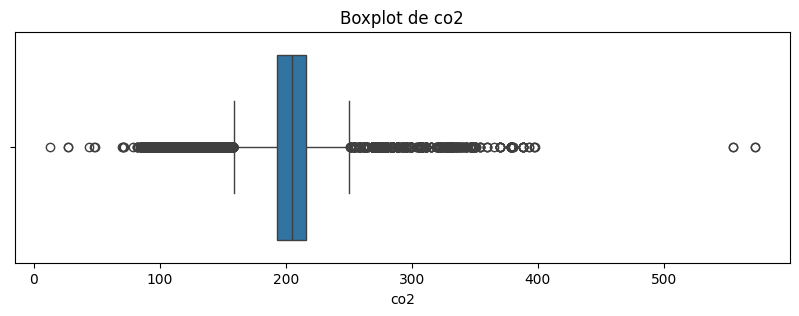

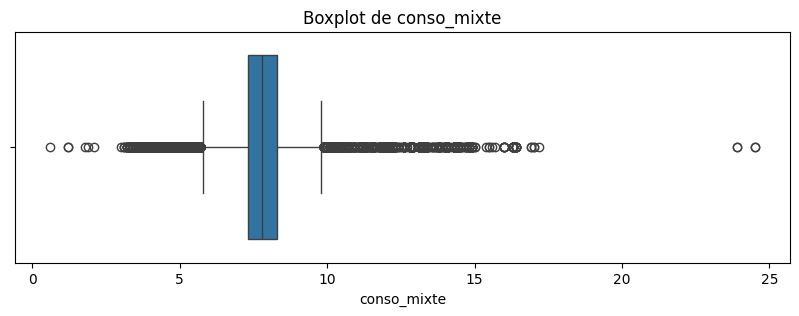

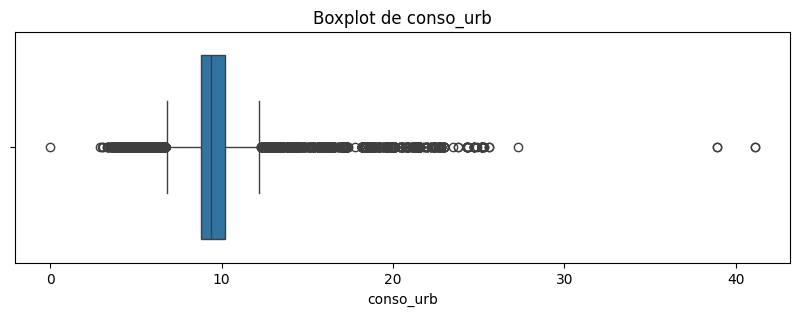

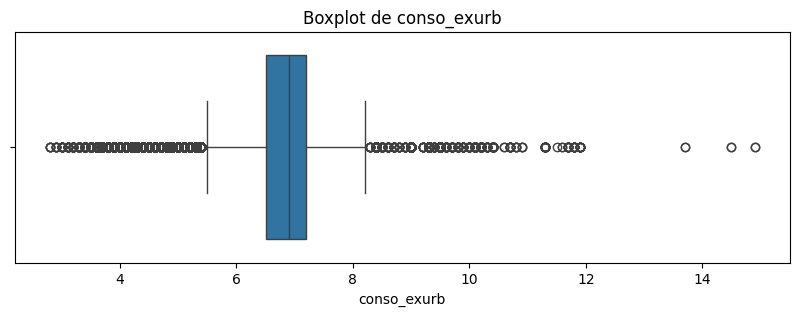

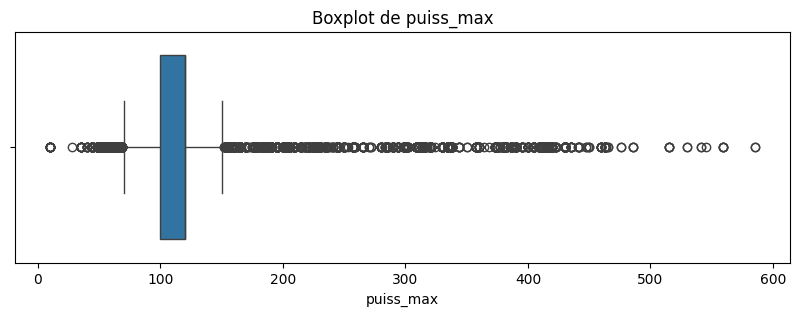

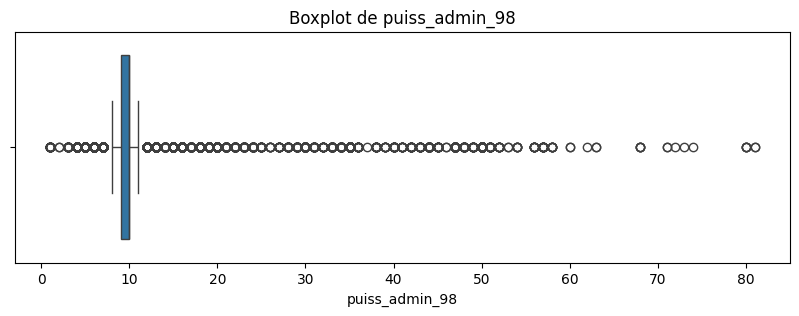

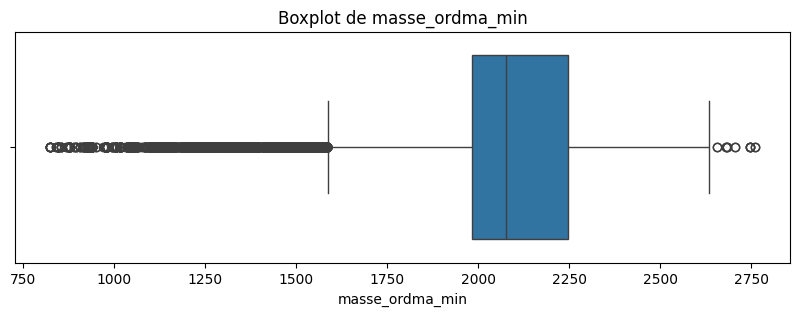

In [29]:
colonnes_numeriques = [
    'co2',
    'conso_mixte',
    'conso_urb',
    'conso_exurb',
    'puiss_max',
    'puiss_admin_98',
    'masse_ordma_min'
]

for col in colonnes_numeriques:
    plt.figure(figsize=(10, 3))
    sns.boxplot(x=df_2014[col])
    plt.title(f"Boxplot de {col}")
    plt.show()

### Approche statistique (méthode de l'IQR)

Afin de compléter l'analyse graphique réalisée à l'aide des boxplots, une détection statistique des valeurs aberrantes est effectuée à l'aide de la méthode de l'intervalle interquartile (IQR).

Cette méthode repose sur le calcul des premier (Q1) et troisième (Q3) quartiles de chaque variable. Les observations situées en dehors des bornes définies par **Q1 − 1,5 × IQR** et **Q3 + 1,5 × IQR**, où **IQR = Q3 − Q1**, sont considérées comme des valeurs aberrantes.

L'objectif est de confirmer, de manière quantitative, la présence de valeurs extrêmes observées lors de l'analyse graphique et d'évaluer leur importance dans les principales variables numériques du jeu de données.

In [30]:
variables = [
    "co2",
    "conso_mixte",
    "conso_urb",
    "conso_exurb",
    "puiss_max",
    "puiss_admin_98",
    "masse_ordma_min"
]

resultats_iqr = []

for var in variables:
    Q1 = df_2014[var].quantile(0.25)
    Q3 = df_2014[var].quantile(0.75)
    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    masque = (df_2014[var] < borne_inf) | (df_2014[var] > borne_sup)

    nb_outliers = masque.sum()
    pourcentage = nb_outliers / len(df_2014) * 100

    resultats_iqr.append({
        "Variable": var,
        "Nombre d'outliers": nb_outliers,
        "% d'outliers": round(pourcentage, 2)
    })

pd.DataFrame(resultats_iqr)

,Variable,Nombre d'outliers,% d'outliers
0,co2,8128,14.77
1,conso_mixte,6989,12.70
2,conso_urb,6715,12.20
3,conso_exurb,8311,15.10
4,puiss_max,7307,13.28
5,puiss_admin_98,13418,24.38
6,masse_ordma_min,3953,7.18


Les approches graphique et statistique sont complémentaires et conduisent aux mêmes conclusions. Les boxplots mettent en évidence la présence de valeurs extrêmes, tandis que la méthode de l'intervalle interquartile (IQR) confirme quantitativement leur présence sur plusieurs variables numériques.

Ces observations peuvent correspondre à des véhicules présentant des caractéristiques particulières (puissance élevée, masse importante ou forte consommation). Leur identification comme valeurs atypiques selon la méthode IQR ne signifie donc pas nécessairement qu'il s'agit d'erreurs de saisie ou d'incohérences dans les données.

En conséquence, aucune suppression ni traitement spécifique des valeurs aberrantes n'a été réalisé à ce stade. Leur conservation permet de préserver la diversité des profils de véhicules présents dans le jeu de données et d'évaluer leur impact lors de la phase de modélisation.

## Analyse des variables catégorielles

In [31]:
variables_cat = [
    'lib_mrq',
    'lib_mod_doss',
    'lib_mod',
    'dscom',
    'cnit',
    'tvv',
    'cod_cbr',
    'hybride',
    'Carrosserie',
    'gamme'
]

for col in variables_cat:
    print(f"\n{col}")
    print(df_2014[col].nunique())


lib_mrq
46

lib_mod_doss
483

lib_mod
434

dscom
3837

cnit
54982

tvv
35430

cod_cbr
13

hybride
2

Carrosserie
11

gamme
7


In [32]:
df_2014["co2"].isna().sum()

np.int64(34)

Une analyse du nombre de modalités a été réalisée sur les variables catégorielles du jeu de données.

Les variables `cnit` et `tvv` présentent une cardinalité particulièrement élevée, avec respectivement 54 982 et 35 430 modalités. Les variables `dscom`, `lib_mod` et `lib_mod_doss` comportent également un nombre important de modalités. Leur encodage One-Hot pourrait entraîner une forte augmentation de la dimension du jeu de données.

À l'inverse, les variables `cod_cbr`, `hybride`, `Carrosserie` et `gamme` présentent un nombre limité de modalités et constituent des candidates pertinentes pour un encodage classique.

Le Target Encoding représente une alternative intéressante pour certaines variables à forte cardinalité, puisqu'il permet de les transformer sans multiplier le nombre de colonnes. Son utilisation devra toutefois être évaluée en tenant compte du risque de surapprentissage et de fuite de données.

## Standardisation des variables numériques

Les principales variables numériques du dataset ont été identifiées et préparées pour une future phase de modélisation. La standardisation n'a pas été appliquée à ce stade du projet car elle doit être réalisée après la séparation des jeux d'entraînement et de test afin d'éviter toute fuite d'information.

Cette transformation sera intégrée au pipeline de prétraitement lors de l'étape de modélisation pour les algorithmes qui y sont sensibles, tels que les régressions linéaires, les méthodes à noyau ou les algorithmes basés sur les distances.

# Préparation des données pour la modélisation

## Séparation de la variable cible et des variables explicatives

### Vérification et traitement de la variable cible

La variable cible (`co2`) est indispensable à l'entraînement des modèles de régression. Les observations pour lesquelles cette valeur est absente ne peuvent pas être utilisées, puisqu'il n'existe aucune valeur de référence à prédire.

Les lignes présentant une valeur manquante pour `co2` sont donc supprimées avant la séparation entre les variables explicatives (`X`) et la variable cible (`y`).

In [33]:
# Vérification des valeurs manquantes de la variable cible

print("Valeurs manquantes dans co2 :", df_2014["co2"].isna().sum())

Valeurs manquantes dans co2 : 34


In [34]:
# Suppression des observations sans variable cible

df_2014 = df_2014.dropna(subset=["co2"]).reset_index(drop=True)

print("Valeurs manquantes dans co2 :", df_2014["co2"].isna().sum())
print("Dimensions du jeu de données :", df_2014.shape)

Valeurs manquantes dans co2 : 0
Dimensions du jeu de données : (55003, 23)


Après suppression des observations dont la variable cible est manquante, le jeu de données destiné à la modélisation contient désormais **55 010 observations**.

In [35]:
# Variable cible
y = df_2014["co2"]

# Variables explicatives
X = df_2014.drop(columns=["co2"])

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (55003, 22)
Dimensions de y : (55003,)


Avant toute étape de modélisation, le jeu de données est séparé entre les variables explicatives (X) et la variable cible (y). Cette séparation permet de distinguer les variables utilisées pour prédire les émissions de CO₂ de la variable à expliquer. Les transformations nécessitant un apprentissage des données (imputation, encodage et standardisation) seront appliquées ultérieurement, après la séparation des jeux d'entraînement et de test, afin d'éviter tout risque de data leakage.

Le découpage conserve `test_size=0.20` et `random_state=42`. Pour une comparaison rigoureuse avec le notebook principal, il faut s’assurer que les mêmes observations sont réparties entre entraînement et test et que la sélection des variables est identique. Les métriques historiques du notebook ne sont pas réutilisées automatiquement.


In [36]:
# Séparation du jeu de données
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test  :", X_test.shape)
print("Dimensions de y_train :", y_train.shape)
print("Dimensions de y_test  :", y_test.shape)

Dimensions de X_train : (44002, 22)
Dimensions de X_test  : (11001, 22)
Dimensions de y_train : (44002,)
Dimensions de y_test  : (11001,)


Le jeu de données est divisé en un ensemble d'entraînement (80 %) et un ensemble de test (20 %). Conformément aux bonnes pratiques en Machine Learning, toutes les transformations nécessitant un apprentissage des données (imputation, encodage et standardisation) seront désormais ajustées uniquement sur le jeu d'entraînement, puis appliquées au jeu de test, afin d'éviter tout risque de data leakage.

## Imputation des valeurs manquantes

Les stratégies d'imputation retenues lors de l'analyse exploratoire sont désormais préparées conformément aux bonnes pratiques du Machine Learning. Les statistiques d'imputation (médianes globales ou conditionnelles) sont calculées uniquement à partir du jeu d'entraînement (`X_train`). Elles seront ensuite utilisées pour imputer les valeurs manquantes des jeux d'entraînement et de test, afin d'éviter toute fuite de données (*data leakage*).

In [37]:
# Médiane globale de CONSO_MIXTE calculée sur le jeu d'entraînement
conso_mixte_mediane = X_train["conso_mixte"].median()

# Médiane globale de PTCL calculée sur le jeu d'entraînement
ptcl_mediane = X_train["ptcl"].median()

# Médianes de NOX par type de carburant
nox_medianes = X_train.groupby("cod_cbr")["nox"].median()

# Médianes de CO_TYP_1 par type de carburant
co_typ1_medianes = X_train.groupby("cod_cbr")["co_typ_1"].median()

# Vérification des statistiques d'imputation calculées sur X_train

In [38]:
print("CONSO_MIXTE :", conso_mixte_mediane)

print("PTCL :", ptcl_mediane)

print("\nNOX :")
print(nox_medianes)

print("\nCO_TYP_1 :")
print(co_typ1_medianes)

CONSO_MIXTE : 7.800000191
PTCL : 0.001

NOX :
cod_cbr
EE       0.008
EH       0.007
ES       0.030
ES/GN    0.036
ES/GP    0.018
FE       0.020
GH       0.061
GL       0.036
GN       0.022
GN/ES    0.031
GO       0.214
GP/ES    0.023
Name: nox, dtype: float64

CO_TYP_1 :
cod_cbr
EE       0.1780
EH       0.1870
ES       0.2375
ES/GN    0.3050
ES/GP    0.3010
FE       0.6320
GH       0.2220
GL       0.0200
GN       0.3700
GN/ES    0.2580
GO       0.1000
GP/ES    0.3820
Name: co_typ_1, dtype: float64


### Application de l'imputation

In [39]:
# -----------------------
# Imputation de CONSO_MIXTE
# -----------------------

X_train["conso_mixte"] = X_train["conso_mixte"].fillna(conso_mixte_mediane)
X_test["conso_mixte"] = X_test["conso_mixte"].fillna(conso_mixte_mediane)

# -----------------------
# Imputation de PTCL
# -----------------------

X_train["ptcl"] = X_train["ptcl"].fillna(ptcl_mediane)
X_test["ptcl"] = X_test["ptcl"].fillna(ptcl_mediane)

# Médianes globales de secours pour les cas particuliers (calculées sur le jeu d'entraînement)
nox_mediane_globale = X_train["nox"].median()
co_typ1_mediane_globale = X_train["co_typ_1"].median()

# -----------------------
# Imputation de NOX
# -----------------------

X_train["nox"] = X_train["nox"].fillna(
    X_train["cod_cbr"].map(nox_medianes)
)

X_test["nox"] = X_test["nox"].fillna(
    X_test["cod_cbr"].map(nox_medianes)
)

# Cas particuliers : absence de médiane pour un type de carburant
# Imputation à l'aide de la médiane globale du jeu d'entraînement
X_train["nox"] = X_train["nox"].fillna(nox_mediane_globale)
X_test["nox"] = X_test["nox"].fillna(nox_mediane_globale)

# -----------------------
# Imputation de CO_TYP_1
# -----------------------

X_train["co_typ_1"] = X_train["co_typ_1"].fillna(
    X_train["cod_cbr"].map(co_typ1_medianes)
)

X_test["co_typ_1"] = X_test["co_typ_1"].fillna(
    X_test["cod_cbr"].map(co_typ1_medianes)
)

# Cas particuliers : absence de médiane pour un type de carburant
# Imputation à l'aide de la médiane globale du jeu d'entraînement
X_train["co_typ_1"] = X_train["co_typ_1"].fillna(co_typ1_mediane_globale)
X_test["co_typ_1"] = X_test["co_typ_1"].fillna(co_typ1_mediane_globale)

In [40]:
print("Valeurs manquantes dans X_train :")
print(X_train[["conso_mixte", "ptcl", "nox", "co_typ_1"]].isna().sum())

print("\nValeurs manquantes dans X_test :")
print(X_test[["conso_mixte", "ptcl", "nox", "co_typ_1"]].isna().sum())

Valeurs manquantes dans X_train :
conso_mixte    0
ptcl           0
nox            0
co_typ_1       0
dtype: int64

Valeurs manquantes dans X_test :
conso_mixte    0
ptcl           0
nox            0
co_typ_1       0
dtype: int64


## Sélection des variables numériques

Après le traitement des valeurs manquantes, une analyse complémentaire des variables numériques a été réalisée afin d'identifier les variables potentiellement redondantes ou présentant une faible valeur ajoutée pour la modélisation.

Cette étape a pour objectif de simplifier le jeu de données, de limiter la redondance entre les variables explicatives et de conserver uniquement les variables les plus pertinentes au regard des émissions de CO₂.

Les décisions présentées ci-dessous s'appuient à la fois sur les analyses statistiques réalisées, les corrélations observées et les connaissances métier.

## Variable `champ_v9`

In [41]:
# Observer la variable
print("Nombre de modalités :", X_train["champ_v9"].nunique())
print()

X_train["champ_v9"].value_counts().head(10)

Nombre de modalités : 32



champ_v9
"715/2007*692/2008EURO5    19168
"715/2007*195/2013EURO5    11913
"715/2007*566/2011EURO5     3869
"2005/55*2008/74EURO5       1505
"2005/55*2008/74EEV         1461
"715/2007*195/2013EURO6     1333
"715/2007*630/2012EURO5     1057
715/2007*630/2012EURO5       652
715/2007*692/2008EURO5       616
715/2007*195/2013EURO5       582
Name: count, dtype: int64

La variable `champ_v9` correspond à une référence réglementaire décrivant les normes d'homologation européennes applicables aux véhicules (par exemple : `715/2007*195/2013EURO5`).

Bien que cette information puisse présenter un intérêt d'un point de vue réglementaire, elle constitue une variable textuelle dont les modalités correspondent à des références d'homologation européennes. Son interprétation est complexe et certaines informations qu'elle contient peuvent être partiellement représentées par d'autres variables environnementales du jeu de données, telles que les émissions de NOx (`nox`), de particules (`ptcl`) ou de monoxyde de carbone (`co_typ_1`).

Dans le cadre de cette première approche, nous avons choisi de ne pas retenir cette variable afin de simplifier le jeu de données. Son intérêt prédictif pourrait néanmoins être évalué ultérieurement, notamment à l'aide du Target Encoding.

## Variables `puiss_admin_98` et `puiss_max`

La variable `puiss_admin_98` correspond à la puissance administrative (chevaux fiscaux), tandis que `puiss_max` représente la puissance maximale réelle du moteur exprimée en kilowatts (kW).

Une analyse de corrélation a été réalisée afin d'évaluer le niveau de redondance entre ces deux variables.

In [42]:
# Calcul de la corrélation
X_train[["puiss_admin_98", "puiss_max"]].corr()

,puiss_admin_98,puiss_max
puiss_admin_98,1.00000,0.97301
puiss_max,0.97301,1.00000


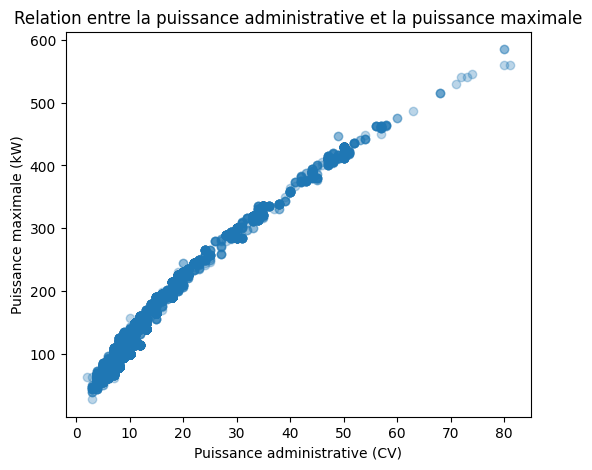

In [43]:
# Visualisation
plt.figure(figsize=(6, 5))
plt.scatter(
    X_train["puiss_admin_98"],
    X_train["puiss_max"],
    alpha=0.3
)

plt.xlabel("Puissance administrative (CV)")
plt.ylabel("Puissance maximale (kW)")
plt.title("Relation entre la puissance administrative et la puissance maximale")

plt.show()

La matrice de corrélation met en évidence une corrélation très élevée (**0,973**) entre `puiss_admin_98` et `puiss_max`.

Cette forte corrélation indique que les deux variables véhiculent une information très similaire. Afin de limiter la redondance entre les variables explicatives, seule la variable `puiss_max`, correspondant à la puissance réelle du moteur, sera conservée pour la modélisation.

## Variables de consommation

Le jeu de données contient trois variables décrivant la consommation de carburant dans différents contextes de conduite :

- `conso_urb` : consommation en cycle urbain ;
- `conso_exurb` : consommation en cycle extra-urbain ;
- `conso_mixte` : consommation en cycle mixte.

Une analyse de corrélation a été réalisée afin d'évaluer le niveau de redondance entre ces trois variables.

In [44]:
# Matrice de corrélation
X_train[
    ["conso_urb", "conso_exurb", "conso_mixte"]
].corr()

,conso_urb,conso_exurb,conso_mixte
conso_urb,1.000000,0.860078,0.970635
conso_exurb,0.860078,1.000000,0.956295
conso_mixte,0.970635,0.956295,1.000000


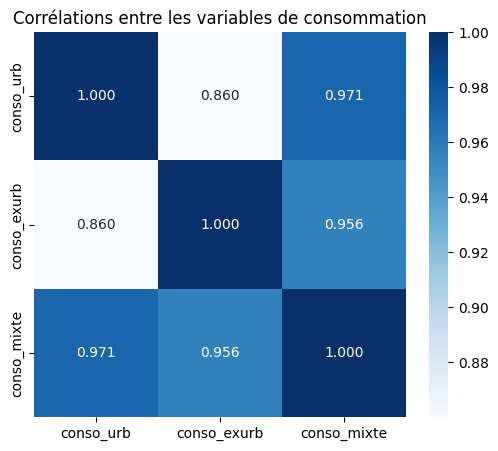

In [45]:
# Heatmap
plt.figure(figsize=(6,5))

sns.heatmap(
    X_train[
        ["conso_urb", "conso_exurb", "conso_mixte"]
    ].corr(),
    annot=True,
    cmap="Blues",
    fmt=".3f"
)

plt.title("Corrélations entre les variables de consommation")
plt.show()

La matrice de corrélation met en évidence une forte redondance entre les trois mesures de consommation.

En particulier, `conso_mixte` présente une très forte corrélation avec :

- `conso_urb` (**0,971**) ;
- `conso_exurb` (**0,956**).

Par ailleurs, l'analyse exploratoire réalisée précédemment a montré que `conso_mixte` est également la variable de consommation la plus fortement corrélée aux émissions de CO₂.

Au regard de ces résultats, seule la variable `conso_mixte` est conservée pour la modélisation. Les variables `conso_urb` et `conso_exurb` seront supprimées afin de limiter la redondance entre les variables explicatives.

## Variables de masse

## Variables `masse_ordma_min` et `masse_ordma_max`

Les variables `masse_ordma_min` et `masse_ordma_max` représentent respectivement la masse minimale et la masse maximale homologuées du véhicule.

Une analyse de corrélation a été réalisée afin d'évaluer le niveau de redondance entre ces deux variables avant d'envisager une éventuelle suppression.

In [46]:
# Corrélation
X_train[["masse_ordma_min", "masse_ordma_max"]].corr()

,masse_ordma_min,masse_ordma_max
masse_ordma_min,1.000000,0.792372
masse_ordma_max,0.792372,1.000000


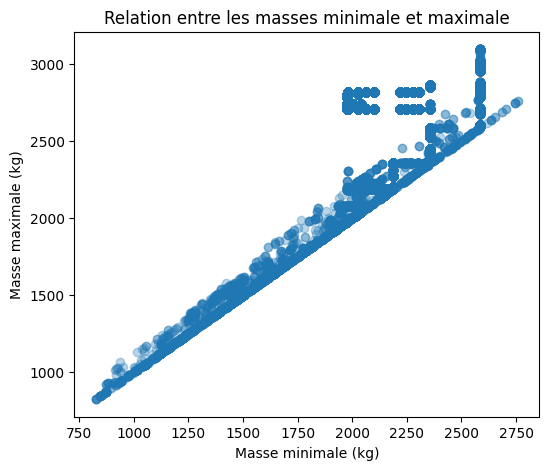

In [47]:
# Nuage de points
plt.figure(figsize=(6,5))

plt.scatter(
    X_train["masse_ordma_min"],
    X_train["masse_ordma_max"],
    alpha=0.3
)

plt.xlabel("Masse minimale (kg)")
plt.ylabel("Masse maximale (kg)")
plt.title("Relation entre les masses minimale et maximale")

plt.show()

La matrice de corrélation met en évidence une corrélation de **0,792** entre `masse_ordma_min` et `masse_ordma_max`.

Bien que ces deux variables soient liées, leur corrélation reste nettement inférieure à celle observée pour les variables de puissance ou de consommation. Elles peuvent donc apporter une information complémentaire et sont toutes les deux conservées pour la modélisation.

### Synthèse de la sélection des variables

L'analyse des variables explicatives a permis d'identifier plusieurs variables présentant une forte redondance ou dont la conservation n'a pas été jugée nécessaire dans le cadre de cette première approche.

Les variables `champ_v9`, `puiss_admin_98`, `conso_urb` et `conso_exurb` ne seront pas conservées pour la modélisation.

À l'inverse, les variables `puiss_max`, `conso_mixte`, `masse_ordma_min` et `masse_ordma_max` sont conservées en raison de leur pertinence métier et des résultats des analyses de corrélation. Les deux variables de masse sont notamment maintenues afin de préserver des informations potentiellement complémentaires pour la prédiction des émissions de CO₂.

## Sélection des variables textuelles

Les variables textuelles présentant un grand nombre de modalités ont fait l'objet d'une analyse spécifique afin d'évaluer leur intérêt pour la modélisation. Pour chacune d'elles, le nombre de modalités, leur fréquence et leur caractère potentiellement redondant ont été étudiés afin de déterminer si leur conservation était pertinente.

In [48]:
print("Nombre de modalités :", df_2014["cnit"].nunique())
print()

df_2014["cnit"].value_counts().head(10)

Nombre de modalités : 54948



cnit
M10FATVP0005418    2
M10FATVP026F862    2
M10FATVP007R335    2
M10ALFVP000P446    2
M10ALFVP000P445    2
M10FATVP0262849    2
M10FATVP0263850    2
M10FATVP0267854    2
M10FATVP0265852    2
M10FATVP008N683    2
Name: count, dtype: int64

La variable `cnit` présente **54 948 modalités pour 55 003 observations**, ce qui montre qu'il s'agit d'un identifiant technique quasi unique.

Son encodage One-Hot entraînerait une augmentation considérable du nombre de variables. Bien que le Target Encoding permette d'éviter cette augmentation de dimension, la très faible fréquence des modalités limiterait la fiabilité des statistiques calculées par catégorie et présenterait un risque important de surapprentissage.

Cette variable ne sera donc pas retenue pour la phase de modélisation.

In [49]:
print("Nombre de modalités :", df_2014["tvv"].nunique())
print()

df_2014["tvv"].value_counts().head(10)

Nombre de modalités : 35402



tvv
639/2KAA31280N1M3G2S39    4
639/2KAA31280N1M3G2S29    4
639/2LAA31305N2M3D2W27    4
639/2LAA31305N2M3G2W27    4
639/2LAA31280N3M3D2S28    4
639/2LAA31280N3M3J2S28    4
639/2KAA31280N3M3J2U39    4
639/2KAA31305N3M3G2V29    4
639/2LAA31305N3M3J2V27    4
639/2LAA31280N1M3D2U38    4
Name: count, dtype: int64

La variable `tvv` présente **35 402 modalités pour 55 003 observations**. Chaque modalité correspond à une référence technique très spécifique et apparaît rarement dans le jeu de données.

Un encodage One-Hot entraînerait une forte augmentation de la dimension du jeu de données. Bien que le Target Encoding permette de limiter cette augmentation, la faible fréquence des modalités rendrait les statistiques calculées par catégorie peu fiables et augmenterait le risque de surapprentissage.

Cette variable ne sera donc pas retenue pour la modélisation.

In [50]:
print("Nombre de modalités :", df_2014["dscom"].nunique())
print()

df_2014["dscom"].value_counts().head(10)

Nombre de modalités : 3817



dscom
VIANO 2.2 CDI                  5874
VIANO 2.0 CDI                  3903
COMBI 116 CDI                  3754
COMBI 113 CDI                  2620
VIANO 3.0 CDI                  1608
SPRINTER COMBI 213 CDI - 32    1548
SPRINTER COMBI 213 CDI - 43    1258
SPRINTER COMBI 213 CDI - 37    1111
SPRINTER COMBI 316 CDI - 37    1074
VIANO 2.2 CDI 4x4               954
Name: count, dtype: int64

La variable `dscom` présente **3 817 modalités**, correspondant aux désignations commerciales des véhicules.

Elle regroupe plusieurs informations (modèle, motorisation, version commerciale) susceptibles d'être partiellement redondantes avec d'autres variables du jeu de données.

Afin de limiter cette redondance potentielle et de conserver un jeu de données simplifié, **nous avons décidé de supprimer `dscom` pour la modélisation**.

Son intérêt prédictif pourra être réévalué ultérieurement, notamment avec le Target Encoding.

In [51]:
print("Nombre de modalités :", df_2014["lib_mod"].nunique())
print()

df_2014["lib_mod"].value_counts().head(10)

Nombre de modalités : 427



lib_mod
VIANO       14031
CRAFTER     13210
VITO         9890
SPRINTER     8155
E 200         468
C 180         292
C 200         258
E 220         240
E 250         228
C 220         166
Name: count, dtype: int64

La variable `lib_mod` présente **427 modalités** correspondant aux modèles de véhicules. La majorité des observations est concentrée sur quelques modèles, notamment VIANO, CRAFTER, VITO et SPRINTER.

Bien que cette variable puisse contenir des informations pertinentes pour la prédiction des émissions de CO₂, elle présente une redondance potentielle avec d'autres variables descriptives, notamment `lib_mrq` et `dscom`.

Dans le cadre de cette première approche, nous avons choisi de **ne pas retenir `lib_mod` pour la modélisation**, afin de limiter les redondances potentielles et de conserver un jeu de données simplifié.

Son intérêt prédictif pourrait être évalué ultérieurement à l'aide du Target Encoding.

In [52]:
print("Nombre de modalités :", df_2014["lib_mod_doss"].nunique())
print()

df_2014["lib_mod_doss"].value_counts().head(10)

Nombre de modalités : 475



lib_mod_doss
VIANO         14031
CRAFTER       13210
VITO           9890
SPRINTER       8155
CLASSE E       1348
CLASSE C        943
CLASSE S        425
CLASSE CLS      196
CLASSE B        180
CLASSE A        176
Name: count, dtype: int64

La variable `lib_mod_doss` présente **475 modalités** correspondant aux modèles de véhicules.

Les modalités les plus fréquentes sont identiques à celles observées pour `lib_mod`, ce qui suggère une forte redondance entre ces deux variables.

Dans le cadre de cette première approche, nous avons décidé de **supprimer `lib_mod_doss` pour la modélisation**, afin de limiter les redondances potentielles et de conserver un jeu de données simplifié.

Son intérêt prédictif pourrait être réévalué ultérieurement, notamment avec le Target Encoding.

## Synthèse de la sélection des variables textuelles

L'analyse des principales variables textuelles a permis d'évaluer leur intérêt potentiel pour la modélisation, en tenant compte de leur cardinalité, de leur nature et des redondances possibles avec d'autres variables explicatives.

Les variables `cnit` et `tvv` ont été écartées en raison de leur très forte cardinalité et de la faible fréquence de leurs modalités, qui présentent notamment un risque de surapprentissage avec le Target Encoding.

Les variables `dscom`, `lib_mod` et `lib_mod_doss` ont également été écartées dans cette première approche afin de limiter les redondances potentielles et de simplifier le jeu de données.

À l'inverse, la variable `lib_mrq`, dont la cardinalité reste raisonnable (46 modalités) et qui présente un intérêt métier, est conservée pour l'encodage.

## Application des décisions de sélection des variables

Les analyses précédentes ont permis d'identifier les variables à conserver ainsi que celles à écarter. Les décisions retenues sont désormais appliquées aux jeux d'entraînement et de test afin d'obtenir un ensemble de variables cohérent avant l'encodage des variables catégorielles.

Cette étape permet de réduire la redondance entre les variables explicatives et de simplifier le jeu de données tout en conservant les informations les plus pertinentes pour la modélisation.

In [53]:
# Variables supprimées à l'issue de la sélection

variables_a_supprimer = [

    # Variables numériques
    "champ_v9",
    "puiss_admin_98",
    "conso_urb",
    "conso_exurb",

    # Variables textuelles
    "cnit",
    "tvv",
    "dscom",
    "lib_mod",
    "lib_mod_doss"
]

X_train = X_train.drop(columns=variables_a_supprimer)
X_test = X_test.drop(columns=variables_a_supprimer)

print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test  :", X_test.shape)

Dimensions de X_train : (44002, 13)
Dimensions de X_test  : (11001, 13)


Conformément aux décisions prises lors de la sélection des variables, les variables numériques et textuelles jugées peu pertinentes ou redondantes ont été supprimées des jeux d'entraînement et de test.

Les jeux de données obtenus sont désormais constitués uniquement des variables retenues pour la modélisation. Ils seront utilisés dans l'étape suivante pour l'encodage des variables catégorielles.

## Vérification de l'absence de valeurs manquantes

In [54]:
# Vérification de l'absence de valeurs manquantes

print("Valeurs manquantes dans X_train :")
print(X_train.isna().sum().sort_values(ascending=False))

print("\nValeurs manquantes dans X_test :")
print(X_test.isna().sum().sort_values(ascending=False))

Valeurs manquantes dans X_train :
lib_mrq              0
cod_cbr              0
hybride              0
puiss_max            0
typ_boite_nb_rapp    0
conso_mixte          0
co_typ_1             0
nox                  0
ptcl                 0
masse_ordma_min      0
masse_ordma_max      0
Carrosserie          0
gamme                0
dtype: int64

Valeurs manquantes dans X_test :
lib_mrq              0
cod_cbr              0
hybride              0
puiss_max            0
typ_boite_nb_rapp    0
conso_mixte          0
co_typ_1             0
nox                  0
ptcl                 0
masse_ordma_min      0
masse_ordma_max      0
Carrosserie          0
gamme                0
dtype: int64


L'imputation des valeurs manquantes a été réalisée avec succès sur les jeux d'entraînement et de test. Une vérification après la sélection des variables confirme qu'aucune valeur manquante ne subsiste dans les données destinées à la modélisation.

Les statistiques d'imputation ont été calculées exclusivement sur le jeu d'entraînement puis appliquées au jeu de test, conformément aux bonnes pratiques de prétraitement, afin d'éviter tout risque de data leakage.

# Encodage des variables catégorielles

L'encodage des variables catégorielles constitue une étape essentielle du prétraitement des données avant la modélisation.

Dans le notebook principal, les variables catégorielles ont été transformées à l'aide d'un One-Hot Encoding. Bien que cette méthode soit simple et largement utilisée, elle peut entraîner une augmentation importante du nombre de variables, en particulier lorsque certaines variables présentent un grand nombre de modalités.

À la demande de Nicolas Mormiche, cette expérience vise à évaluer une approche alternative reposant sur le Target Encoding. Cette méthode remplace chaque modalité d'une variable catégorielle par une statistique calculée à partir de la variable cible, généralement sa moyenne, afin de conserver davantage d'information tout en limitant la dimension du jeu de données.

Les mêmes variables catégorielles que dans le notebook principal sont conservées pour cette expérimentation : lib_mrq, cod_cbr, hybride, Carrosserie, gamme et typ_boite_nb_rapp. Ainsi, la seule différence entre les deux approches réside dans la méthode d'encodage, ce qui permet de comparer objectivement leurs performances.

Comme pour le One-Hot Encoding, le Target Encoding est ajusté uniquement sur le jeu d'entraînement (X_train) à l'aide des valeurs de y_train, puis appliqué au jeu de test (X_test) afin d'éviter toute fuite d'information (data leakage).

### Définition des variables à encoder

In [55]:
# Variables catégorielles à encoder

variables_a_encoder = [
    "lib_mrq",
    "cod_cbr",
    "hybride",
    "Carrosserie",
    "gamme",
    "typ_boite_nb_rapp"
]

variables_a_encoder

['lib_mrq', 'cod_cbr', 'hybride', 'Carrosserie', 'gamme', 'typ_boite_nb_rapp']

### Création du Target Encoder

In [56]:
# Target Encoding : ajustement hors-échantillon pour le jeu d'entraînement
# Le jeu de test est transformé avec un encodeur appris sur tout le train.
from sklearn.model_selection import KFold

target_encoder = TargetEncoder(cols=variables_a_encoder)
cv_target = KFold(n_splits=5, shuffle=True, random_state=42)
target_encoder


,verbose,0
,cols,"['lib_mrq', 'cod_cbr', ...]"
,drop_invariant,False
,return_df,True
,handle_missing,'value'
,handle_unknown,'value'
,min_samples_leaf,20
,smoothing,10
,hierarchy,None


### Apprentissage de l'encodeur

In [57]:
# Encodage out-of-fold : chaque ligne de train est encodée sans sa propre cible.
X_train_brut = X_train.copy()
X_test_brut = X_test.copy()
X_train_encode = X_train_brut.copy()

for indices_apprentissage, indices_validation in cv_target.split(X_train_brut):
    encodeur_fold = TargetEncoder(cols=variables_a_encoder)
    encodeur_fold.fit(
        X_train_brut.iloc[indices_apprentissage],
        y_train.iloc[indices_apprentissage]
    )
    X_train_encode.iloc[indices_validation] = encodeur_fold.transform(
        X_train_brut.iloc[indices_validation]
    ).to_numpy()

# Ajustement final sur tout le train, uniquement pour transformer le test.
target_encoder.fit(X_train_brut, y_train)


,verbose,0
,cols,"['lib_mrq', 'cod_cbr', ...]"
,drop_invariant,False
,return_df,True
,handle_missing,'value'
,handle_unknown,'value'
,min_samples_leaf,20
,smoothing,10
,hierarchy,None


### Transformation des jeux de données

In [58]:
# Jeux encodés utilisés par les modèles ci-dessous
X_train = X_train_encode.astype(float)
X_test = target_encoder.transform(X_test_brut).astype(float)


### Vérification finale des jeux de données

In [59]:
print("Dimensions X_train :", X_train.shape)
print("Dimensions X_test  :", X_test.shape)

display(X_train.head())

Dimensions X_train : (44002, 13)
Dimensions X_test  : (11001, 13)


,lib_mrq,cod_cbr,hybride,puiss_max,typ_boite_nb_rapp,conso_mixte,co_typ_1,nox,ptcl,masse_ordma_min,masse_ordma_max,Carrosserie,gamme
24728,207.963981,202.217340,202.267869,120.0,195.859470,7.2,0.046,0.197,0.000,2076.0,2185.0,210.506529,209.009292
65,130.843039,203.870070,202.267869,125.0,162.610382,5.2,0.440,0.030,0.001,1380.0,1380.0,141.535447,205.447592
52499,201.788917,201.968775,202.059810,120.0,195.818892,7.4,0.401,0.213,0.001,2246.0,2709.0,210.321168,205.176044
22245,207.966143,202.199683,202.382420,120.0,195.957263,7.7,0.175,0.226,0.001,2186.0,2355.0,210.526759,208.798209
24305,207.963981,202.217340,202.267869,120.0,195.859470,7.7,0.046,0.197,0.000,2186.0,2350.0,210.506529,209.009292


In [60]:
print("=" * 60)
print("Vérification finale des jeux de données")
print("=" * 60)

print(f"Dimensions X_train : {X_train.shape}")
print(f"Dimensions X_test  : {X_test.shape}")

print(f"\nValeurs manquantes X_train : {X_train.isna().sum().sum()}")
print(f"Valeurs manquantes X_test  : {X_test.isna().sum().sum()}")

print("\nTypes de variables :")
display(X_train.dtypes)


print("\nValeurs infinies dans X_train :", np.isinf(X_train.to_numpy()).sum())
print("Valeurs infinies dans X_test  :", np.isinf(X_test.to_numpy()).sum())

Vérification finale des jeux de données
Dimensions X_train : (44002, 13)
Dimensions X_test  : (11001, 13)

Valeurs manquantes X_train : 0
Valeurs manquantes X_test  : 0

Types de variables :


lib_mrq              float64
cod_cbr              float64
hybride              float64
puiss_max            float64
typ_boite_nb_rapp    float64
conso_mixte          float64
co_typ_1             float64
nox                  float64
ptcl                 float64
masse_ordma_min      float64
masse_ordma_max      float64
Carrosserie          float64
gamme                float64
dtype: object


Valeurs infinies dans X_train : 0
Valeurs infinies dans X_test  : 0


## Régression linéaire

La régression linéaire constitue le modèle de référence (baseline) de cette étude. Son principe repose sur l'hypothèse d'une relation linéaire entre les variables explicatives et les émissions de CO₂.

Dans cette expérience, le modèle est entraîné sur un jeu de données prétraité à l'aide du Target Encoding, afin d'évaluer l'impact de cette méthode d'encodage des variables catégorielles sur les performances du modèle.

Les résultats obtenus seront ensuite comparés à ceux issus du One-Hot Encoding, utilisé dans le notebook principal, afin d'analyser l'influence de la stratégie d'encodage sur la qualité des prédictions.

## Évaluation du modèle

### Entraînement du modèle

In [61]:
# Initialisation du modèle
reg_lin = LinearRegression()

# Entraînement
reg_lin.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### Prédictions

In [62]:
# Prédictions sur le jeu de test
y_pred_lin = reg_lin.predict(X_test)

### Performances du modèle

In [63]:
# Calcul des métriques de performance

mae_lin = mean_absolute_error(y_test, y_pred_lin)
rmse_lin = np.sqrt(mean_squared_error(y_test, y_pred_lin))
r2_lin = r2_score(y_test, y_pred_lin)
mape_lin = mean_absolute_percentage_error(y_test, y_pred_lin)

# Affichage des performances

print(f"MAE  : {mae_lin:.2f}")
print(f"RMSE : {rmse_lin:.2f}")
print(f"R²   : {r2_lin:.4f}")
print(f"MAPE : {mape_lin:.4f}")

MAE  : 2.74
RMSE : 4.36
R²   : 0.9837
MAPE : 0.0146


### Analyse des résultats

La régression linéaire associée au Target Encoding obtient de bonnes performances sur le jeu de test, avec un **R² de 0,9837**, une **MAE de 2,74 g/km** et une **RMSE de 4,36 g/km**.

La MAPE de **1,46 %** confirme que les erreurs relatives de prédiction restent globalement faibles.

Ces résultats montrent qu'une régression linéaire peut obtenir de bonnes performances avec les 13 variables explicatives retenues et encodées. La forte relation entre `conso_mixte` et les émissions de CO₂ contribue probablement à ces performances.

Une comparaison avec les résultats obtenus à l'aide du One-Hot Encoding permettra d'évaluer l'intérêt du Target Encoding.

### Comparaison avec un modèle de référence (DummyRegressor)

In [64]:
# Initialisation du modèle de référence
dummy = DummyRegressor(strategy="mean")

# Entraînement
dummy.fit(X_train, y_train)

# Prédictions
y_pred_dummy = dummy.predict(X_test)

# Calcul des métriques
mae_dummy = mean_absolute_error(y_test, y_pred_dummy)
rmse_dummy = np.sqrt(mean_squared_error(y_test, y_pred_dummy))
r2_dummy = r2_score(y_test, y_pred_dummy)
mape_dummy = mean_absolute_percentage_error(y_test, y_pred_dummy)

# Tableau comparatif des performances
comparaison_modeles = pd.DataFrame({
    "Modèle": ["DummyRegressor", "Régression linéaire + Target Encoding"],
    "MAE": [mae_dummy, mae_lin],
    "RMSE": [rmse_dummy, rmse_lin],
    "R²": [r2_dummy, r2_lin],
    "MAPE (%)": [mape_dummy * 100, mape_lin * 100]
})

# Affichage du tableau
display(comparaison_modeles.round(4))

,Modèle,MAE,RMSE,R²,MAPE (%)
0,DummyRegressor,22.4525,34.1556,-0.0000,12.9776
1,Régression linéaire + Target Encoding,2.7405,4.3584,0.9837,1.4641


### Comparaison des performances

La comparaison avec le modèle de référence `DummyRegressor`, qui prédit systématiquement la moyenne des émissions de CO₂ du jeu d'entraînement, met en évidence les bonnes performances de la régression linéaire associée au Target Encoding.

Le `DummyRegressor` obtient une **MAE de 22,45 g/km**, une **RMSE de 34,16 g/km** et un **R² proche de zéro**.

À l'inverse, la régression linéaire avec Target Encoding obtient :

- **MAE : 2,74 g/km**
- **RMSE : 4,36 g/km**
- **R² : 0,9837**
- **MAPE : 1,46 %**

La régression linéaire permet ainsi de réduire l'erreur absolue moyenne d'environ **87,8 %** par rapport au modèle de référence.

Ces résultats montrent que le modèle exploite efficacement les informations contenues dans les variables explicatives pour prédire les émissions de CO₂.

Toutefois, cette comparaison ne permet pas à elle seule de mesurer le gain apporté par le Target Encoding. Une comparaison avec les performances obtenues avec le One-Hot Encoding sera nécessaire pour évaluer l'intérêt de cette méthode d'encodage.


### Analyse de la capacité de généralisation

In [65]:
# Évaluation des performances sur les jeux d'entraînement et de test

print(f"Score R² sur le jeu d'entraînement : {reg_lin.score(X_train, y_train):.4f}")
print(f"Score R² sur le jeu de test         : {reg_lin.score(X_test, y_test):.4f}")

Score R² sur le jeu d'entraînement : 0.9820
Score R² sur le jeu de test         : 0.9837


### Analyse de la généralisation du modèle

La régression linéaire avec Target Encoding obtient un **R² de 0,9820 sur le jeu d'entraînement** et de **0,9837 sur le jeu de test**.

L'écart entre les deux scores est très faible (0,0017), ce qui indique une bonne stabilité des performances et ne met pas en évidence de surapprentissage significatif.

Le score légèrement supérieur sur le jeu de test peut notamment s'expliquer par les différences entre les échantillons et par la stratégie d'encodage utilisée.

Ces résultats suggèrent que le modèle possède une bonne capacité de généralisation sur les données étudiées.


### Valeurs réelles vs valeurs prédites - Régression linéaire (Target Encoding)


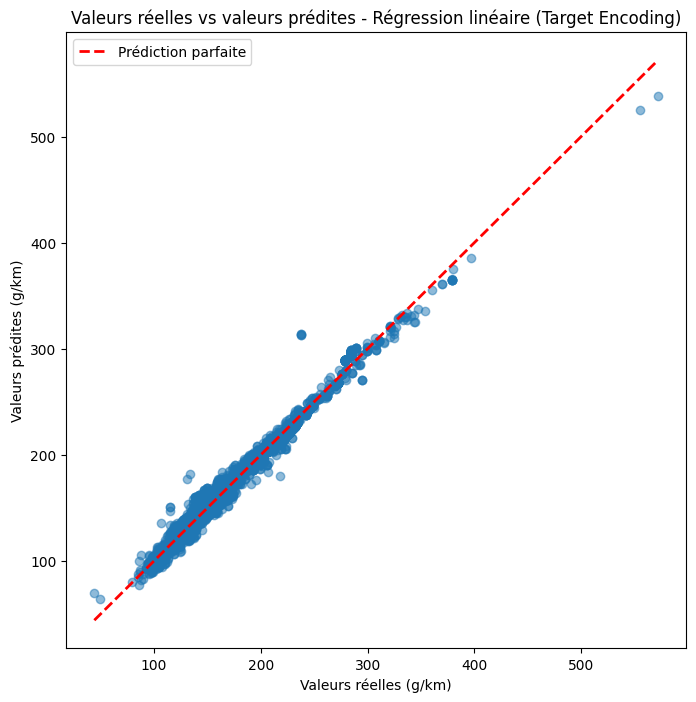

In [66]:
plt.figure(figsize=(8, 8))

# Valeurs réelles vs valeurs prédites
plt.scatter(
    y_test,
    y_pred_lin,
    alpha=0.5
)

# Ligne de prédiction parfaite
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2,
    label="Prédiction parfaite"
)

plt.xlabel("Valeurs réelles (g/km)")
plt.ylabel("Valeurs prédites (g/km)")
plt.title("Valeurs réelles vs valeurs prédites - Régression linéaire (Target Encoding)")
plt.legend()

plt.show()

### Analyse des résultats

Le graphique comparant les valeurs réelles et les valeurs prédites montre que **la majorité des observations se concentrent autour de la diagonale représentant une prédiction parfaite**.

Cette proximité traduit une bonne capacité du modèle de régression linéaire avec Target Encoding à prédire les émissions de CO₂.

Quelques écarts sont toutefois observés, notamment pour les véhicules présentant des émissions très élevées, pour lesquels le modèle tend à sous-estimer légèrement les valeurs réelles.

Ces observations graphiques sont cohérentes avec les performances obtenues sur le jeu de test, notamment un **R² de 0,9837**, une **MAE de 2,74 g/km** et une **RMSE de 4,36 g/km**.

Dans l'ensemble, le modèle présente une bonne précision prédictive, malgré quelques erreurs ponctuelles sur les valeurs extrêmes.


### Analyse des résidus

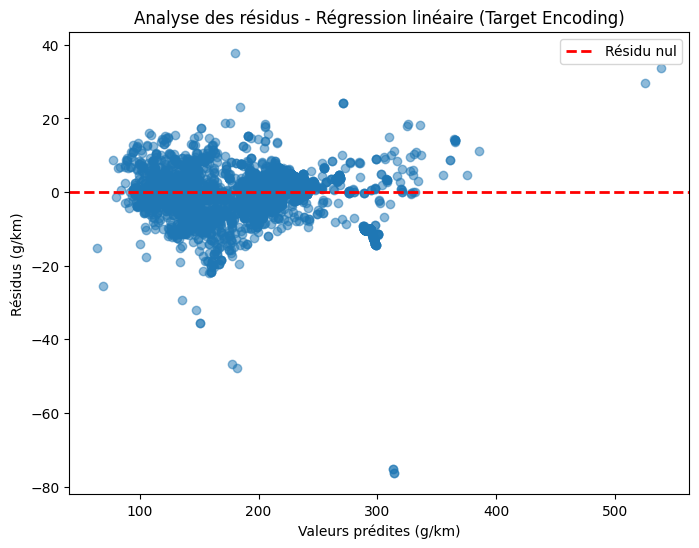

In [67]:
# Calcul des résidus
residus = y_test - y_pred_lin

plt.figure(figsize=(8, 6))

# Valeurs prédites vs résidus
plt.scatter(
    y_pred_lin,
    residus,
    alpha=0.5
)

# Ligne représentant un résidu nul
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Résidu nul"
)

plt.xlabel("Valeurs prédites (g/km)")
plt.ylabel("Résidus (g/km)")
plt.title("Analyse des résidus - Régression linéaire (Target Encoding)")
plt.legend()

plt.show()

### Analyse des résidus

Le graphique des résidus de la régression linéaire avec Target Encoding montre que **la majorité des erreurs sont concentrées autour de zéro**, ce qui confirme la bonne précision globale du modèle.

Cependant, la dispersion des résidus n'est pas parfaitement homogène selon les valeurs prédites. Certaines zones présentent une variabilité plus importante, ce qui peut suggérer la présence de relations non linéaires ou de caractéristiques insuffisamment prises en compte par le modèle.

Quelques résidus extrêmes sont également observés, notamment des valeurs proches de **−75 g/km** et de **+40 g/km**, indiquant des erreurs de prédiction importantes pour certaines observations.

Malgré ces écarts ponctuels, les résidus restent majoritairement proches de zéro, ce qui est cohérent avec les bonnes performances obtenues sur le jeu de test (**R² = 0,9837**, **MAE = 2,74 g/km**).

Ces résultats montrent que la régression linéaire constitue une approche performante, tout en laissant entrevoir un potentiel d'amélioration avec des modèles capables de capturer des relations plus complexes, notamment les méthodes d'ensemble.


### Courbe d'apprentissage


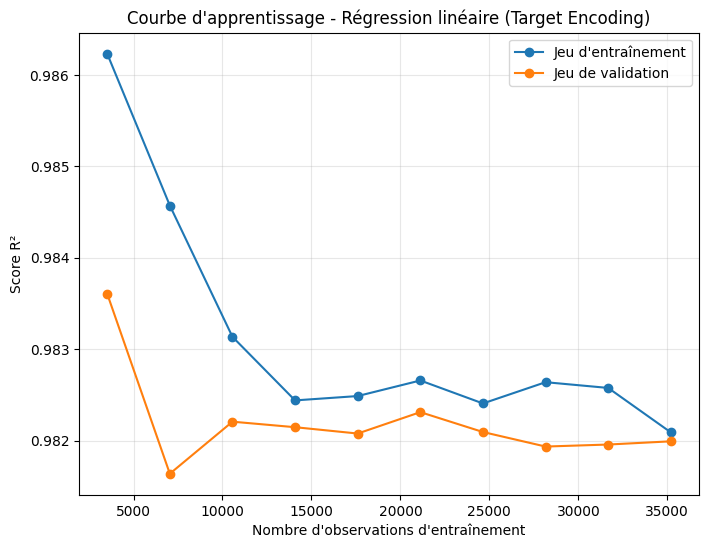

In [68]:
# Encodage ajusté à l'intérieur de chaque pli de validation croisée
from sklearn.pipeline import Pipeline
pipeline_cv = Pipeline([
    ("target_encoding", TargetEncoder(cols=variables_a_encoder)),
    ("modele", LinearRegression())
])

# Calcul des courbes d'apprentissage
train_sizes, train_scores, test_scores = learning_curve(
    estimator=pipeline_cv,
    X=X_train_brut,
    y=y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

# Moyenne des scores
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

# Graphique
plt.figure(figsize=(8, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Jeu d'entraînement"
)

plt.plot(
    train_sizes,
    test_mean,
    marker="o",
    label="Jeu de validation"
)

plt.xlabel("Nombre d'observations d'entraînement")
plt.ylabel("Score R²")
plt.title("Courbe d'apprentissage - Régression linéaire (Target Encoding)")
plt.legend()

plt.grid(alpha=0.3)

plt.show()

### Analyse des courbes d'apprentissage

Les courbes d'apprentissage montrent une convergence rapide des performances sur les jeux d'entraînement et de validation.

Le score R² sur le jeu d'entraînement diminue progressivement lorsque le nombre d'observations augmente, tandis que celui du jeu de validation se stabilise autour de **0,982**.

L'écart entre les deux courbes devient très faible, ce qui indique une **bonne capacité de généralisation** et ne met pas en évidence de surapprentissage significatif.

Les performances se stabilisent lorsque la taille du jeu d'entraînement augmente, ce qui suggère que le modèle exploite efficacement les informations disponibles et que l'ajout de nouvelles observations n'apporterait pas nécessairement un gain important avec cette configuration.

Avec des scores R² proches de **0,982**, ces résultats confirment que la régression linéaire associée au Target Encoding constitue une approche performante pour prédire les émissions de CO₂.

Une comparaison avec les performances obtenues avec le One-Hot Encoding permettra d'évaluer plus précisément l'intérêt de cette méthode d'encodage.

## Régression Ridge

La régression Ridge est une extension de la régression linéaire qui intègre une pénalisation de type L2 sur les coefficients du modèle.

Cette régularisation permet de limiter l'influence des variables fortement corrélées et de réduire le risque de surapprentissage. Elle reste pertinente dans ce contexte afin d'évaluer si une pénalisation des coefficients peut améliorer les performances du modèle obtenu avec le Target Encoding des variables catégorielles.

L'objectif est d'évaluer si cette régularisation améliore les performances prédictives par rapport à la régression linéaire classique.

### Entraînement du modèle

In [69]:
# Initialisation du modèle
ridge = Ridge(alpha=1.0)

# Entraînement
ridge.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


### Prédictions

In [70]:
# Prédictions sur le jeu de test
y_pred_ridge = ridge.predict(X_test)

### Performances du modèle

In [71]:
# Calcul des métriques

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)
mape_ridge = mean_absolute_percentage_error(y_test, y_pred_ridge)

# Affichage des performances

print(f"MAE  : {mae_ridge:.2f}")
print(f"RMSE : {rmse_ridge:.2f}")
print(f"R²   : {r2_ridge:.4f}")
print(f"MAPE : {mape_ridge:.4f}")

MAE  : 2.84
RMSE : 4.46
R²   : 0.9829
MAPE : 0.0151


### Analyse des résultats

La régression Ridge associée au Target Encoding obtient de bonnes performances sur le jeu de test, avec un **R² de 0,9829**, une **MAE de 2,84 g/km**, une **RMSE de 4,46 g/km** et une **MAPE de 1,51 %**.

Ces résultats restent proches de ceux obtenus avec la régression linéaire classique, qui présente toutefois des performances légèrement supérieures sur les quatre métriques.

Dans cette configuration, la régularisation L2 appliquée par Ridge (`alpha=1.0`) n'apporte donc pas d'amélioration des performances prédictives.

Une optimisation du paramètre `alpha`, associée à une standardisation des variables, pourrait être envisagée ultérieurement pour évaluer plus précisément l'intérêt de cette régularisation.

### Comparaison avec le DummyRegressor

In [72]:
comparaison_dummy_ridge = pd.DataFrame({
    "Modèle": ["DummyRegressor", "Ridge"],
    "MAE": [mae_dummy, mae_ridge],
    "RMSE": [rmse_dummy, rmse_ridge],
    "R²": [r2_dummy, r2_ridge],
    "MAPE": [mape_dummy, mape_ridge]
})

comparaison_dummy_ridge = comparaison_dummy_ridge.round(4)

comparaison_dummy_ridge

,Modèle,MAE,RMSE,R²,MAPE
0,DummyRegressor,22.4525,34.1556,-0.0000,0.1298
1,Ridge,2.8368,4.4620,0.9829,0.0151


### Analyse des résultats

La comparaison avec le `DummyRegressor` met en évidence les bonnes performances de la régression Ridge associée au Target Encoding.

Le modèle de référence, qui prédit systématiquement la moyenne des émissions de CO₂ du jeu d'entraînement, obtient une **MAE de 22,45 g/km**, une **RMSE de 34,16 g/km** et un **R² proche de zéro**.

À l'inverse, la régression Ridge obtient une **MAE de 2,84 g/km**, une **RMSE de 4,46 g/km**, un **R² de 0,9829** et une **MAPE de 1,51 %**.

La régression Ridge permet ainsi de réduire l'erreur absolue moyenne d'environ **87,4 %** par rapport au modèle de référence.

Ces résultats confirment que Ridge exploite efficacement les variables explicatives pour prédire les émissions de CO₂, même si ses performances restent légèrement inférieures à celles de la régression linéaire classique dans cette configuration.


### Analyse de la capacité de généralisation

In [73]:
# Évaluation des performances sur les jeux d'entraînement et de test

print(f"Score R² sur le jeu d'entraînement : {ridge.score(X_train, y_train):.4f}")
print(f"Score R² sur le jeu de test         : {ridge.score(X_test, y_test):.4f}")

Score R² sur le jeu d'entraînement : 0.9814
Score R² sur le jeu de test         : 0.9829


### Analyse de la capacité de généralisation

La régression Ridge associée au Target Encoding obtient un **R² de 0,9814 sur le jeu d'entraînement** et de **0,9829 sur le jeu de test**.

L'écart entre les deux scores est très faible (**0,0015**), ce qui traduit une bonne stabilité des performances et ne met pas en évidence de surapprentissage significatif.

Le score légèrement supérieur sur le jeu de test peut notamment s'expliquer par les différences entre les échantillons et par la stratégie de Target Encoding utilisée, avec un encodage Out-of-Fold pour l'entraînement.

Ces résultats suggèrent que le modèle Ridge possède une **bonne capacité de généralisation** sur les données étudiées.


### Valeurs réelles vs valeurs prédites


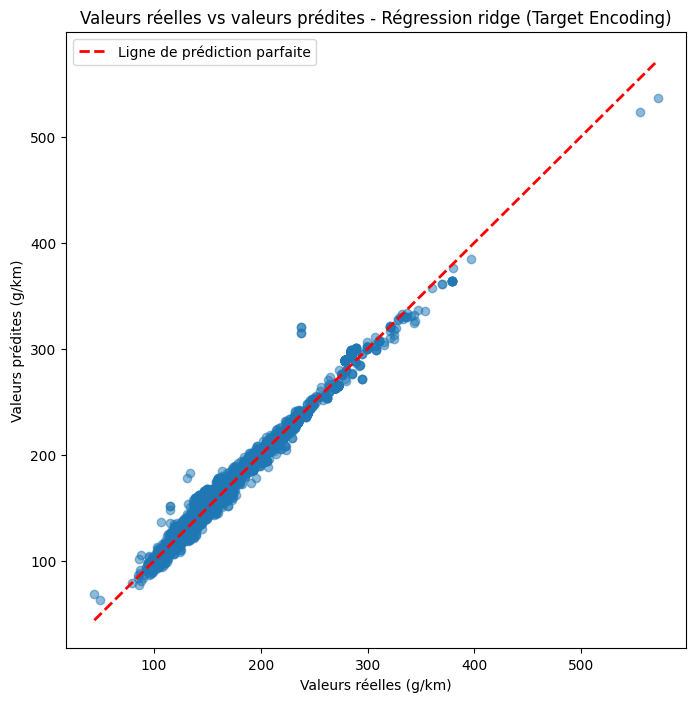

In [74]:
plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    y_pred_ridge,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2,
    label="Ligne de prédiction parfaite"
)

plt.xlabel("Valeurs réelles (g/km)")
plt.ylabel("Valeurs prédites (g/km)")
plt.title("Valeurs réelles vs valeurs prédites - Régression ridge (Target Encoding)")
plt.legend()

plt.show()

### Analyse des résultats

Le graphique comparant les valeurs réelles et les valeurs prédites par la régression Ridge avec Target Encoding montre que **la majorité des observations se concentrent autour de la diagonale représentant une prédiction parfaite**.

Cette proximité traduit une bonne capacité du modèle à prédire les émissions de CO₂.

Quelques écarts sont néanmoins observés, notamment pour les véhicules présentant des émissions très élevées, pour lesquels le modèle tend à sous-estimer les valeurs réelles.

Ces observations sont cohérentes avec les performances obtenues sur le jeu de test, notamment un **R² de 0,9829**, une **MAE de 2,84 g/km** et une **RMSE de 4,46 g/km**.

Le graphique présente une distribution des prédictions globalement similaire à celle observée avec la régression linéaire classique. La régularisation L2 de Ridge n'apporte donc pas d'amélioration notable dans cette configuration.

Dans l'ensemble, le modèle Ridge présente une bonne précision prédictive, malgré quelques erreurs ponctuelles sur les valeurs extrêmes.


### Analyse des résidus

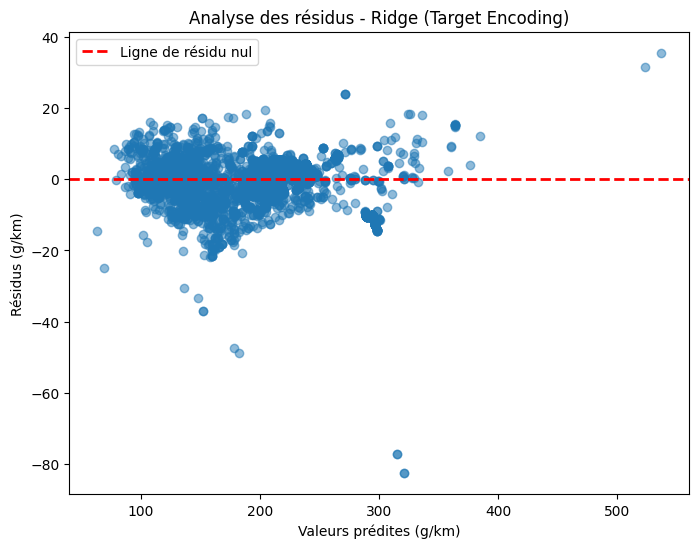

In [75]:
# Calcul des résidus
residus_ridge = y_test - y_pred_ridge

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_ridge,
    residus_ridge,
    alpha=0.5
)

# Ligne horizontale représentant un résidu nul
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Ligne de résidu nul"
)

plt.xlabel("Valeurs prédites (g/km)")
plt.ylabel("Résidus (g/km)")
plt.title("Analyse des résidus - Ridge (Target Encoding)")
plt.legend()

plt.show()

### Analyse des résidus

L'analyse des résidus de la régression Ridge avec Target Encoding montre que **la majorité des erreurs de prédiction se concentrent autour de zéro**, ce qui confirme la bonne précision globale du modèle.

La dispersion des résidus reste relativement limitée pour la majorité des observations. Toutefois, quelques valeurs extrêmes sont visibles, avec des résidus atteignant approximativement **-80 g/km et +35 g/km**.

La répartition des résidus présente également certaines structures, notamment dans les zones de prédiction les plus représentées. Cela suggère que le modèle ne parvient pas à capturer parfaitement toutes les relations entre les variables explicatives et les émissions de CO₂.

Ces observations restent cohérentes avec les performances obtenues sur le jeu de test (**R² = 0,9829 et RMSE = 4,46 g/km**).

Dans l'ensemble, la régression Ridge avec Target Encoding présente une bonne qualité prédictive, malgré quelques erreurs importantes sur certaines observations et des limites liées à son caractère linéaire.


### Courbe d'apprentissage


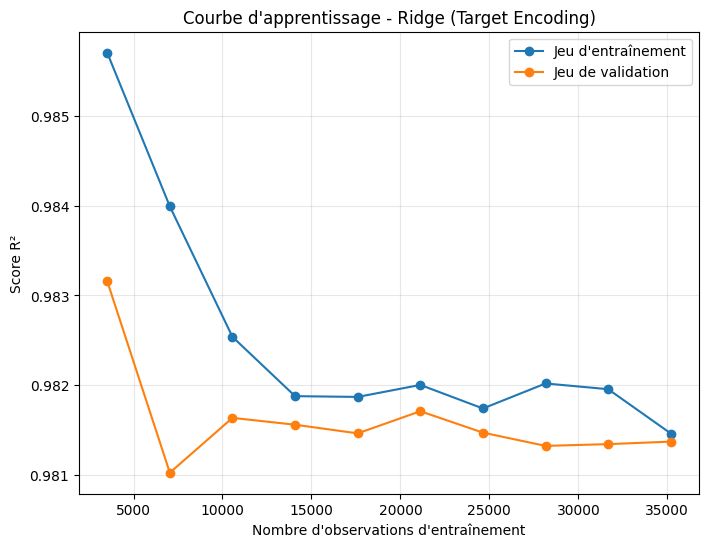

In [76]:
# Encodage ajusté à l'intérieur de chaque pli de validation croisée
from sklearn.pipeline import Pipeline
pipeline_cv = Pipeline([
    ("target_encoding", TargetEncoder(cols=variables_a_encoder)),
    ("modele", Ridge(alpha=1.0))
])


# Calcul des courbes d'apprentissage
train_sizes, train_scores, test_scores = learning_curve(
    estimator=pipeline_cv,
    X=X_train_brut,
    y=y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

# Moyennes des scores
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

# Graphique
plt.figure(figsize=(8,6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Jeu d'entraînement"
)

plt.plot(
    train_sizes,
    test_mean,
    marker="o",
    label="Jeu de validation"
)

plt.xlabel("Nombre d'observations d'entraînement")
plt.ylabel("Score R²")
plt.title("Courbe d'apprentissage - Ridge (Target Encoding)")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

### Analyse de la courbe d'apprentissage

Les courbes d'apprentissage de la régression Ridge avec Target Encoding montrent une **convergence progressive des performances sur les jeux d'entraînement et de validation**.

Pour les petites tailles d'échantillon, le score R² obtenu sur le jeu d'entraînement est légèrement supérieur à celui du jeu de validation. Cet écart diminue progressivement lorsque le nombre d'observations augmente.

À partir d'environ 15 000 observations, les performances se stabilisent, avec des scores R² compris entre **0,981 et 0,982**.

La proximité des deux courbes indique une **bonne capacité de généralisation**, sans signe notable de surapprentissage.

Ces résultats sont cohérents avec les performances obtenues sur le jeu de test (**R² = 0,9829**) et confirment la stabilité du modèle Ridge associé au Target Encoding.

Enfin, les courbes sont très proches de celles obtenues avec la régression linéaire classique, ce qui suggère que la régularisation L2 n'apporte pas d'amélioration significative dans cette configuration.


## Régression Lasso

La régression Lasso est une variante de la régression linéaire qui applique une pénalisation de type L1 sur les coefficients du modèle.

Cette régularisation favorise la sélection automatique des variables en ramenant certains coefficients à zéro. Elle permet ainsi d'identifier les variables les plus influentes tout en simplifiant le modèle. Dans cette expérience, elle permet d'évaluer si cette sélection automatique améliore les performances obtenues avec le Target Encoding des variables catégorielles.

L'objectif est de comparer les performances de la régression Lasso à celles de la régression linéaire et de la régression Ridge afin d'évaluer l'intérêt de cette régularisation dans ce nouveau contexte d'encodage.

### Entraînement du modèle

In [77]:
# Initialisation du modèle
lasso = Lasso(alpha=1.0)

# Entraînement
lasso.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


### Prédictions

In [78]:
# Prédictions sur le jeu de test
y_pred_lasso = lasso.predict(X_test)

### Performances du modèle

In [79]:
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)
mape_lasso = mean_absolute_percentage_error(y_test, y_pred_lasso)

print(f"MAE  : {mae_lasso:.2f}")
print(f"RMSE : {rmse_lasso:.2f}")
print(f"R²   : {r2_lasso:.4f}")
print(f"MAPE : {mape_lasso:.4f}")

MAE  : 3.18
RMSE : 4.73
R²   : 0.9808
MAPE : 0.0168


### Analyse des performances

La régression Lasso associée au Target Encoding obtient une **MAE de 3,18 g/km**, une **RMSE de 4,73 g/km**, un **R² de 0,9808** et une **MAPE de 1,68 %**.

Ces résultats montrent que le modèle explique environ **98,08 % de la variance des émissions de CO₂** sur le jeu de test, avec des erreurs de prédiction globalement limitées.

Les performances restent toutefois légèrement inférieures à celles obtenues avec la régression linéaire classique et la régression Ridge.

Cette différence peut notamment s'expliquer par la régularisation L1 appliquée par Lasso (`alpha=1.0`), qui pénalise les coefficients du modèle et peut réduire sa capacité prédictive.

Dans l'ensemble, le modèle Lasso présente de bonnes performances, mais n'apporte pas d'amélioration par rapport aux deux modèles linéaires précédemment évalués.

### Comparaison avec le DummyRegressor

In [80]:
comparaison_dummy_lasso = pd.DataFrame({
    "Modèle": ["DummyRegressor", "Lasso"],
    "MAE": [mae_dummy, mae_lasso],
    "RMSE": [rmse_dummy, rmse_lasso],
    "R²": [r2_dummy, r2_lasso],
    "MAPE": [mape_dummy, mape_lasso]
})

comparaison_dummy_lasso = comparaison_dummy_lasso.round(4)
comparaison_dummy_lasso

,Modèle,MAE,RMSE,R²,MAPE
0,DummyRegressor,22.4525,34.1556,-0.0000,0.1298
1,Lasso,3.1762,4.7289,0.9808,0.0168


### Analyse des résultats

La comparaison avec le `DummyRegressor` met en évidence les bonnes performances de la régression Lasso associée au Target Encoding.

Le modèle de référence, qui prédit systématiquement la moyenne des émissions de CO₂ du jeu d'entraînement, obtient une **MAE de 22,45 g/km**, une **RMSE de 34,16 g/km** et un **R² proche de zéro**.

À l'inverse, la régression Lasso obtient une **MAE de 3,18 g/km**, une **RMSE de 4,73 g/km**, un **R² de 0,9808** et une **MAPE de 1,68 %**.

La régression Lasso permet ainsi de réduire l'erreur absolue moyenne d'environ **85,9 %** par rapport au modèle de référence.

Ces résultats confirment que Lasso exploite efficacement les variables explicatives pour prédire les émissions de CO₂, même si ses performances restent légèrement inférieures à celles de la régression linéaire classique et de Ridge dans cette configuration.


### Analyse de la capacité de généralisation

In [81]:
# Évaluation des performances sur les jeux d'entraînement et de test

print(f"Score R² sur le jeu d'entraînement : {lasso.score(X_train, y_train):.4f}")
print(f"Score R² sur le jeu de test         : {lasso.score(X_test, y_test):.4f}")

Score R² sur le jeu d'entraînement : 0.9795
Score R² sur le jeu de test         : 0.9808


### Analyse de la capacité de généralisation

La régression Lasso associée au Target Encoding obtient un **R² de 0,9795 sur le jeu d'entraînement** et de **0,9808 sur le jeu de test**.

L'écart entre les deux scores est très faible (**0,0013**), ce qui traduit une bonne stabilité des performances et ne met pas en évidence de surapprentissage significatif.

Le score légèrement supérieur sur le jeu de test peut notamment s'expliquer par les différences entre les échantillons et par la stratégie de Target Encoding utilisée, avec un encodage Out-of-Fold pour l'entraînement.

Bien que les performances soient légèrement inférieures à celles de la régression linéaire classique et de Ridge, ces résultats suggèrent que le modèle Lasso possède une **bonne capacité de généralisation** sur les données étudiées.


### Valeurs réelles vs valeurs prédites


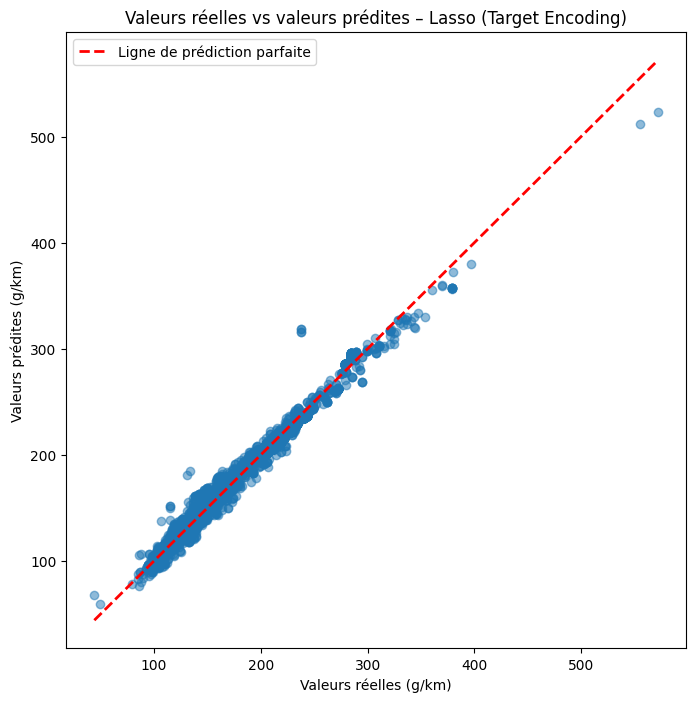

In [82]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    y_pred_lasso,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2,
    label="Ligne de prédiction parfaite"
)

plt.xlabel("Valeurs réelles (g/km)")
plt.ylabel("Valeurs prédites (g/km)")
plt.title("Valeurs réelles vs valeurs prédites – Lasso (Target Encoding)")

plt.legend()

plt.show()

### Analyse des résultats

Le graphique comparant les valeurs réelles et les valeurs prédites par la régression Lasso avec Target Encoding montre que **la majorité des observations se concentrent autour de la diagonale représentant une prédiction parfaite**.

Cette proximité traduit une bonne capacité du modèle à prédire les émissions de CO₂.

Quelques écarts sont néanmoins observés, notamment pour les véhicules présentant des émissions très élevées, pour lesquels le modèle tend à sous-estimer les valeurs réelles.

Ces observations sont cohérentes avec les performances obtenues sur le jeu de test, notamment un **R² de 0,9808**, une **MAE de 3,18 g/km** et une **RMSE de 4,73 g/km**.

Le graphique présente une distribution des prédictions globalement similaire à celle observée avec la régression linéaire classique et Ridge. Toutefois, les métriques montrent que la régularisation L1 de Lasso n'apporte pas d'amélioration des performances prédictives dans cette configuration.

Dans l'ensemble, le modèle Lasso présente une bonne précision prédictive, malgré quelques erreurs ponctuelles sur les valeurs extrêmes.


### Analyse des résidus

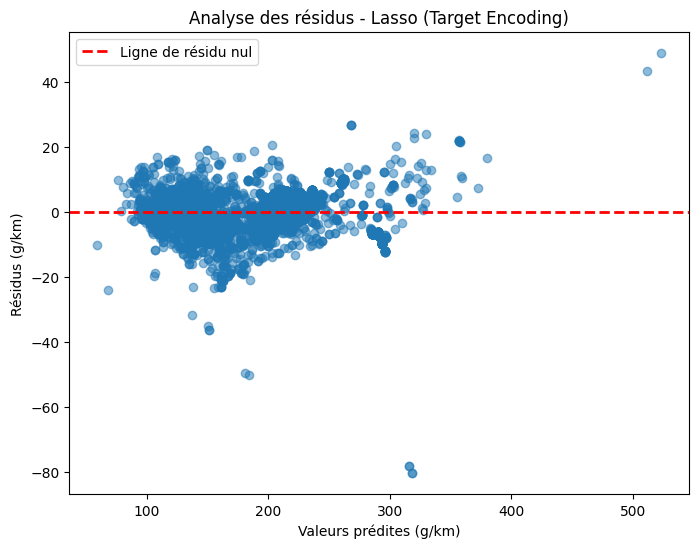

In [83]:
# Calcul des résidus
residus_lasso = y_test - y_pred_lasso

plt.figure(figsize=(8,6))

plt.scatter(
    y_pred_lasso,
    residus_lasso,
    alpha=0.5
)

# Ligne de résidu nul
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Ligne de résidu nul"
)

plt.xlabel("Valeurs prédites (g/km)")
plt.ylabel("Résidus (g/km)")
plt.title("Analyse des résidus - Lasso (Target Encoding)")

plt.legend()

plt.show()

### Analyse des résidus

L'analyse des résidus de la régression Lasso avec Target Encoding montre que **la majorité des erreurs de prédiction se concentrent autour de zéro**, ce qui confirme la bonne précision globale du modèle.

La dispersion des résidus reste relativement limitée pour la majorité des observations. Toutefois, quelques valeurs extrêmes sont visibles, avec des résidus atteignant approximativement **-80 g/km et +50 g/km**.

La répartition des résidus présente également certaines structures, notamment dans les zones de prédiction les plus représentées. Cela suggère que le modèle ne parvient pas à capturer parfaitement toutes les relations entre les variables explicatives et les émissions de CO₂.

Ces observations restent cohérentes avec les performances obtenues sur le jeu de test (**R² = 0,9808 et RMSE = 4,73 g/km**).

Dans l'ensemble, la régression Lasso avec Target Encoding présente une bonne qualité prédictive, malgré quelques erreurs importantes sur certaines observations et des limites liées à son caractère linéaire.

La comparaison avec la régression linéaire classique et Ridge montre toutefois que la régularisation L1 n'améliore pas les performances prédictives dans cette configuration.


### Courbe d'apprentissage


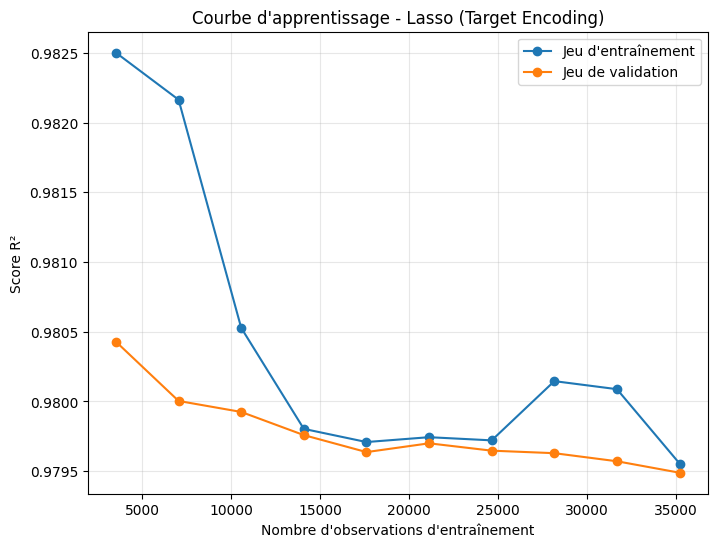

In [84]:
# Encodage ajusté à l'intérieur de chaque pli de validation croisée
from sklearn.pipeline import Pipeline
pipeline_cv = Pipeline([
    ("target_encoding", TargetEncoder(cols=variables_a_encoder)),
    ("modele", Lasso(alpha=1.0))
])

# Calcul des courbes d'apprentissage
train_sizes, train_scores, test_scores = learning_curve(
    estimator=pipeline_cv,
    X=X_train_brut,
    y=y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

# Moyenne des scores
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

# Graphique
plt.figure(figsize=(8,6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Jeu d'entraînement"
)

plt.plot(
    train_sizes,
    test_mean,
    marker="o",
    label="Jeu de validation"
)

plt.xlabel("Nombre d'observations d'entraînement")
plt.ylabel("Score R²")
plt.title("Courbe d'apprentissage - Lasso (Target Encoding)")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

### Analyse de la courbe d'apprentissage

Les courbes d'apprentissage de la régression Lasso avec Target Encoding montrent une **convergence progressive des performances sur les jeux d'entraînement et de validation**.

Pour les petites tailles d'échantillon, le score R² obtenu sur le jeu d'entraînement est légèrement supérieur à celui du jeu de validation. Cet écart diminue progressivement lorsque le nombre d'observations augmente.

À partir d'environ 15 000 observations, les performances se stabilisent autour d'un **R² de 0,980**, avec des variations relativement faibles.

La proximité des deux courbes indique une **bonne capacité de généralisation**, sans signe notable de surapprentissage.

Ces résultats sont cohérents avec les performances obtenues sur le jeu de test (**R² = 0,9808**) et confirment la stabilité du modèle Lasso associé au Target Encoding.

Enfin, les performances restent légèrement inférieures à celles observées avec la régression linéaire classique et Ridge, ce qui suggère que la régularisation L1 n'apporte pas d'amélioration prédictive dans cette configuration.

## Arbre de décision

L'arbre de décision est un modèle non linéaire qui segmente progressivement les données en réalisant une succession de règles de décision. Contrairement aux modèles linéaires, il est capable de capturer des relations complexes entre les variables explicatives et les émissions de CO₂ sans faire d'hypothèse de linéarité.

Ce modèle présente plusieurs avantages : il est capable de modéliser des interactions entre les variables, de prendre en compte des relations non linéaires et de fournir une interprétation intuitive des décisions prises. En contrepartie, un arbre de décision peut être sensible au surapprentissage lorsqu'il n'est pas correctement régularisé.

L'objectif est d'évaluer si cette approche permet d'améliorer les performances prédictives par rapport aux modèles linéaires dans le contexte du Target Encoding.

### Entraînement du modèle

In [85]:
# Initialisation du modèle
tree = DecisionTreeRegressor(random_state=42)

# Entraînement
tree.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


### Prédictions

In [86]:
# Prédictions sur le jeu de test
y_pred_tree = tree.predict(X_test)

### Performances du modèle

In [87]:
mae_tree = mean_absolute_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))
r2_tree = r2_score(y_test, y_pred_tree)
mape_tree = mean_absolute_percentage_error(y_test, y_pred_tree)

print(f"MAE  : {mae_tree:.2f}")
print(f"RMSE : {rmse_tree:.2f}")
print(f"R²   : {r2_tree:.4f}")
print(f"MAPE : {mape_tree:.4f}")

MAE  : 0.11
RMSE : 1.27
R²   : 0.9986
MAPE : 0.0008


### Analyse des performances

L'arbre de décision associé au Target Encoding obtient une **MAE de 0,11 g/km**, une **RMSE de 1,27 g/km**, un **R² de 0,9986** et une **MAPE de 0,08 %**.

Ces résultats montrent que le modèle explique environ **99,86 % de la variance des émissions de CO₂** sur le jeu de test, avec des erreurs de prédiction particulièrement faibles.

Les performances sont nettement supérieures à celles obtenues avec la régression linéaire classique, Ridge et Lasso.

Cette amélioration peut notamment s'expliquer par la capacité des arbres de décision à modéliser des relations non linéaires et des interactions entre les variables explicatives.

Dans cette configuration, l'arbre de décision constitue donc le modèle le plus performant parmi ceux évalués jusqu'à présent avec le Target Encoding.

Toutefois, l'arbre ayant été entraîné sans limitation de profondeur, une analyse de sa capacité de généralisation reste nécessaire afin de vérifier l'absence de surapprentissage.

### Comparaison avec le DummyRegressor

In [88]:
comparaison_dummy_tree = pd.DataFrame({
    "Modèle": ["DummyRegressor", "Arbre de décision"],
    "MAE": [mae_dummy, mae_tree],
    "RMSE": [rmse_dummy, rmse_tree],
    "R²": [r2_dummy, r2_tree],
    "MAPE": [mape_dummy, mape_tree]
})

comparaison_dummy_tree = comparaison_dummy_tree.round(4)
comparaison_dummy_tree

,Modèle,MAE,RMSE,R²,MAPE
0,DummyRegressor,22.4525,34.1556,-0.0000,0.1298
1,Arbre de décision,0.1083,1.2674,0.9986,0.0008


### Analyse des résultats

La comparaison avec le `DummyRegressor` met en évidence les excellentes performances de l'arbre de décision associé au Target Encoding.

Le modèle de référence, qui prédit systématiquement la moyenne des émissions de CO₂ du jeu d'entraînement, obtient une **MAE de 22,45 g/km**, une **RMSE de 34,16 g/km** et un **R² proche de zéro**.

À l'inverse, l'arbre de décision obtient une **MAE de 0,11 g/km**, une **RMSE de 1,27 g/km**, un **R² de 0,9986** et une **MAPE d'environ 0,08 %**.

L'arbre de décision permet ainsi de réduire l'erreur absolue moyenne d'environ **99,5 %** par rapport au modèle de référence.

Ces résultats confirment que l'arbre de décision exploite efficacement les variables explicatives pour prédire les émissions de CO₂ et surpasse nettement les modèles linéaires précédemment évalués.

Toutefois, ces performances particulièrement élevées nécessitent une analyse complémentaire de la capacité de généralisation du modèle, notamment pour vérifier l'absence de surapprentissage.

### Analyse de la capacité de généralisation

In [89]:
# Évaluation des performances sur les jeux d'entraînement et de test

print(f"Score R² sur le jeu d'entraînement : {tree.score(X_train, y_train):.4f}")
print(f"Score R² sur le jeu de test         : {tree.score(X_test, y_test):.4f}")

Score R² sur le jeu d'entraînement : 1.0000
Score R² sur le jeu de test         : 0.9986


### Analyse de la capacité de généralisation

L'arbre de décision associé au Target Encoding obtient un **R² de 1,0000 sur le jeu d'entraînement** et de **0,9986 sur le jeu de test**.

Le score parfait sur le jeu d'entraînement indique que le modèle reproduit très précisément les observations utilisées lors de son apprentissage. Ce résultat est caractéristique d'un arbre de décision entraîné sans limitation de profondeur et peut constituer un signe de surapprentissage.

Toutefois, l'écart entre les deux scores reste très faible (**0,0014**) et les performances sur le jeu de test demeurent particulièrement élevées.

Ces résultats montrent que, malgré sa forte capacité d'ajustement aux données d'entraînement, le modèle conserve une **excellente capacité de généralisation** sur le jeu de test étudié.

Une analyse complémentaire à l'aide de la courbe d'apprentissage permettra d'examiner plus précisément la stabilité des performances et les éventuels signes de surapprentissage.


### Valeurs réelles vs valeurs prédites


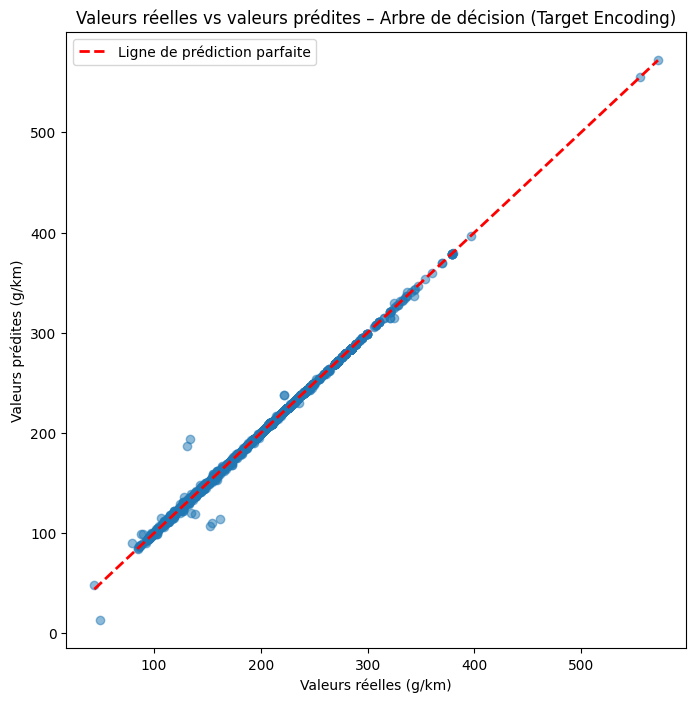

In [90]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    y_pred_tree,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    linewidth=2,
    label="Ligne de prédiction parfaite"
)

plt.xlabel("Valeurs réelles (g/km)")
plt.ylabel("Valeurs prédites (g/km)")
plt.title("Valeurs réelles vs valeurs prédites – Arbre de décision (Target Encoding)")

plt.legend()

plt.show()

### Analyse des valeurs réelles et prédites

Le graphique met en évidence une très forte correspondance entre les émissions réelles de CO₂ et les valeurs prédites par l'arbre de décision associé au Target Encoding.

La grande majorité des observations se situe directement sur la droite de prédiction parfaite, ce qui traduit une excellente précision du modèle.

Quelques écarts ponctuels sont néanmoins visibles, notamment pour certaines observations présentant des émissions comprises entre 100 et 200 g/km. Ces erreurs restent toutefois isolées au regard de l'ensemble des prédictions.

Ces observations sont cohérentes avec les performances obtenues sur le jeu de test, notamment le **R² de 0,9986**, la **MAE de 0,11 g/km** et la **RMSE de 1,27 g/km**.

L'arbre de décision apparaît ainsi particulièrement performant pour prédire les émissions de CO₂. L'analyse des résidus permettra de mieux caractériser les quelques erreurs de prédiction observées.


### Analyse des résidus

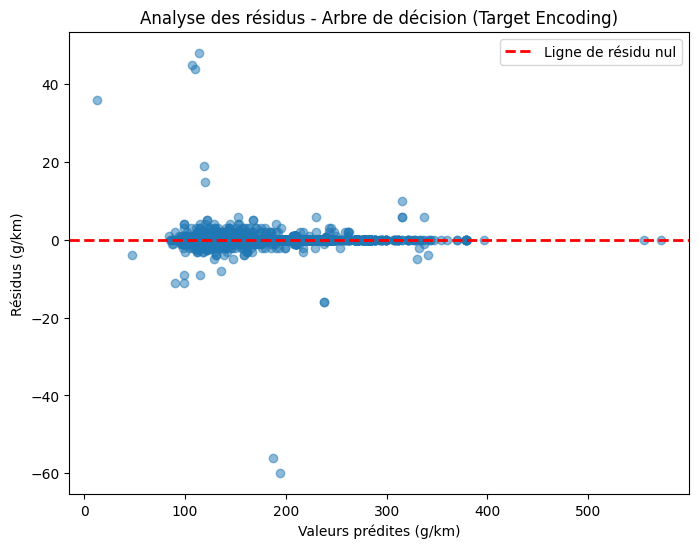

In [91]:
# Calcul des résidus
residus_tree = y_test - y_pred_tree

plt.figure(figsize=(8,6))

plt.scatter(
    y_pred_tree,
    residus_tree,
    alpha=0.5
)

# Ligne représentant un résidu nul
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Ligne de résidu nul"
)

plt.xlabel("Valeurs prédites (g/km)")
plt.ylabel("Résidus (g/km)")
plt.title("Analyse des résidus - Arbre de décision (Target Encoding)")

plt.legend()

plt.show()

### Analyse des résidus

L'analyse des résidus de l'arbre de décision associé au Target Encoding met en évidence une forte concentration des erreurs autour de zéro.

La grande majorité des observations présente des résidus très faibles, ce qui confirme la précision élevée des prédictions obtenues sur le jeu de test.

Contrairement aux modèles linéaires précédemment évalués, la dispersion des résidus apparaît particulièrement réduite sur la majeure partie des valeurs prédites.

Quelques erreurs importantes et isolées subsistent néanmoins, avec des résidus atteignant approximativement **−60 g/km** et **+48 g/km**. Ces observations montrent que le modèle peut encore rencontrer des difficultés sur certains véhicules présentant des caractéristiques particulières.

Dans l'ensemble, ces résultats sont cohérents avec les excellentes performances du modèle (**R² de 0,9986**, **MAE de 0,11 g/km** et **RMSE de 1,27 g/km**).

L'analyse de la courbe d'apprentissage permettra de compléter cette évaluation en examinant la stabilité des performances et les éventuels signes de surapprentissage.


### Courbe d'apprentissage


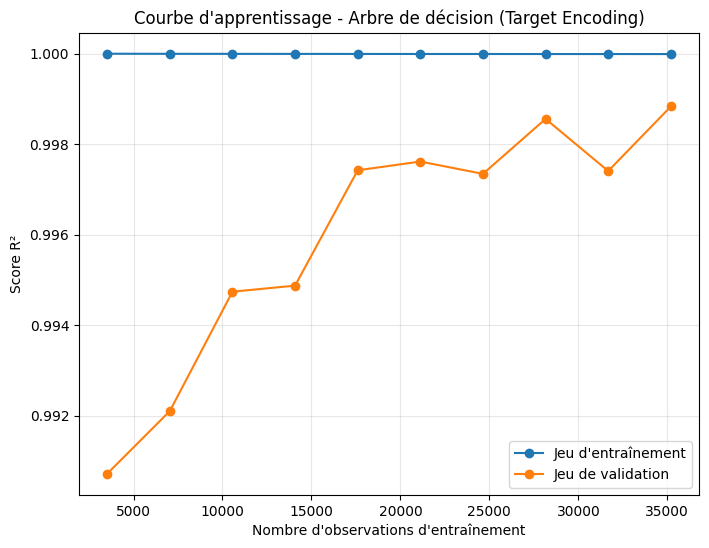

In [92]:
# Encodage ajusté à l'intérieur de chaque pli de validation croisée
from sklearn.pipeline import Pipeline
pipeline_cv = Pipeline([
    ("target_encoding", TargetEncoder(cols=variables_a_encoder)),
    ("modele", DecisionTreeRegressor(random_state=42))
])


# Calcul des courbes d'apprentissage
train_sizes, train_scores, test_scores = learning_curve(
    estimator=pipeline_cv,
    X=X_train_brut,
    y=y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

# Moyenne des scores
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

# Graphique
plt.figure(figsize=(8,6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Jeu d'entraînement"
)

plt.plot(
    train_sizes,
    test_mean,
    marker="o",
    label="Jeu de validation"
)

plt.xlabel("Nombre d'observations d'entraînement")
plt.ylabel("Score R²")
plt.title("Courbe d'apprentissage - Arbre de décision (Target Encoding)")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

### Analyse de la courbe d'apprentissage

La courbe d'apprentissage de l'arbre de décision associé au Target Encoding met en évidence un **R² de 1,0000 sur le jeu d'entraînement**, quelle que soit la quantité de données utilisée.

Ce résultat traduit une capacité d'ajustement très élevée du modèle, caractéristique d'un arbre de décision entraîné sans limitation de profondeur. Il constitue également un signe potentiel de surapprentissage.

En parallèle, le score de validation progresse avec l'augmentation du nombre d'observations, passant d'environ **0,991 à 0,999**.

L'écart entre les performances d'entraînement et de validation diminue progressivement, ce qui indique que le modèle bénéficie de l'augmentation du volume de données et conserve une excellente capacité de généralisation.

Les légères fluctuations observées sur la courbe de validation restent limitées et ne remettent pas en cause la stabilité globale des performances.

Ces résultats confirment les excellentes performances de l'arbre de décision avec Target Encoding, tout en soulignant l'intérêt potentiel d'une régularisation de l'arbre afin de limiter sa complexité.


## Comparaison entre le One-Hot Encoding et le Target Encoding

L'objectif de cette expérience est d'évaluer l'impact du Target Encoding sur les performances des différents modèles de régression, en comparaison avec l'encodage One-Hot utilisé dans le notebook principal.

Le Target Encoding permet de remplacer chaque modalité d'une variable catégorielle par une valeur numérique calculée à partir de la variable cible. Cette approche réduit fortement la dimension du jeu de données et peut améliorer les performances de certains modèles, notamment lorsque les variables catégorielles présentent un grand nombre de modalités.

À l'inverse, le One-Hot Encoding crée une variable binaire pour chaque modalité, ce qui augmente le nombre de variables mais préserve intégralement l'information catégorielle.

L'objectif est donc de déterminer si le Target Encoding constitue une alternative plus performante au One-Hot Encoding pour la prédiction des émissions de CO₂.

## Tableau comparatif One-Hot Encoding vs Target Encoding

In [93]:
# Comparaison des performances des deux approches d'encodage
# Résultats One-Hot issus du notebook principal
# Résultats Target Encoding issus de la présente expérience

comparaison_encodages = pd.DataFrame({
    "Modèle": [
        "Régression linéaire",
        "Ridge",
        "Lasso",
        "Arbre de décision"
    ],

    "R² One-Hot": [
        0.9974,
        0.9974,
        0.9923,
        0.9991
    ],

    "R² Target": [
        r2_lin,
        r2_ridge,
        r2_lasso,
        r2_tree
    ],

    "MAE One-Hot": [
        1.0922,
        1.0925,
        1.9067,
        0.0872
    ],

    "MAE Target": [
        mae_lin,
        mae_ridge,
        mae_lasso,
        mae_tree
    ]
})

# Écarts de performance : Target Encoding - One-Hot Encoding
comparaison_encodages["Écart R²"] = (
    comparaison_encodages["R² Target"]
    - comparaison_encodages["R² One-Hot"]
)

comparaison_encodages["Écart MAE"] = (
    comparaison_encodages["MAE Target"]
    - comparaison_encodages["MAE One-Hot"]
)

display(comparaison_encodages.round(4))

,Modèle,R² One-Hot,R² Target,MAE One-Hot,MAE Target,Écart R²,Écart MAE
0,Régression linéaire,0.9974,0.9837,1.0922,2.7405,-0.0137,1.6483
1,Ridge,0.9974,0.9829,1.0925,2.8368,-0.0145,1.7443
2,Lasso,0.9923,0.9808,1.9067,3.1762,-0.0115,1.2695
3,Arbre de décision,0.9991,0.9986,0.0872,0.1083,-0.0005,0.0211


### Analyse comparative des modèles

La comparaison des performances entre le One-Hot Encoding et le Target Encoding met en évidence des résultats très satisfaisants pour les deux approches, avec toutefois un avantage systématique pour le One-Hot Encoding dans les configurations évaluées.

**Régression linéaire :** le One-Hot Encoding obtient un R² de 0,9974 contre 0,9837 avec le Target Encoding. La MAE passe de 1,09 à 2,74 g/km. Cette différence montre que la régression linéaire bénéficie davantage de la représentation catégorielle utilisée dans le notebook principal.

**Ridge :** les résultats suivent la même tendance, avec un R² de 0,9974 pour le One-Hot Encoding contre 0,9829 pour le Target Encoding. La MAE augmente de 1,09 à 2,84 g/km.

**Lasso :** le One-Hot Encoding conserve également l'avantage, avec un R² de 0,9923 contre 0,9808 et une MAE de 1,91 contre 3,18 g/km.

**Arbre de décision :** les performances des deux approches sont particulièrement proches. Le One-Hot Encoding obtient un R² de 0,9991 contre 0,9986 avec le Target Encoding, tandis que la MAE passe de 0,0872 à 0,1083 g/km. L'arbre de décision apparaît ainsi comme le modèle le moins affecté par le changement de représentation des variables catégorielles.

Dans l'ensemble, les résultats montrent que le **Target Encoding permet de conserver des performances prédictives très élevées**, malgré des scores légèrement inférieurs à ceux du pipeline One-Hot.

Cette comparaison doit néanmoins être interprétée avec prudence : les pipelines évalués ne reposent pas sur des prétraitements strictement identiques, notamment concernant certaines variables explicatives et la standardisation des modèles régularisés. Les écarts observés ne peuvent donc pas être attribués exclusivement au choix de l'encodage.


## Conclusion générale

Cette expérimentation avait pour objectif d'évaluer l'intérêt du **Target Encoding** comme alternative au **One-Hot Encoding** pour la prédiction des émissions de CO₂ des véhicules.

Les résultats obtenus mettent en évidence deux enseignements principaux : une réduction importante de la dimension du jeu de données et le maintien de performances prédictives élevées.

### Réduction de la dimension

Le Target Encoding permet de passer de **93 variables explicatives avec le One-Hot Encoding à 13 variables**, soit une réduction de **80 colonnes (environ 86 %)**.

Cette diminution constitue un avantage intéressant pour simplifier la représentation des données et limiter le nombre de variables utilisées par les modèles.

Toutefois, cette réduction ne peut pas être attribuée exclusivement au changement d'encodage, certaines variables explicatives et transformations différant entre les deux pipelines.

### Performances prédictives

Les quatre modèles évalués avec le Target Encoding obtiennent des performances élevées, avec des coefficients de détermination R² compris entre **0,9808 et 0,9986**.

L'**arbre de décision** se distingue particulièrement avec :

- **MAE : 0,1083 g/km**
- **RMSE : 1,2674 g/km**
- **R² : 0,9986**
- **MAPE : environ 0,08 %**

La comparaison avec les résultats du notebook principal montre néanmoins que le **One-Hot Encoding conserve un avantage sur les quatre modèles étudiés**, aussi bien en matière de R² que de MAE.

Les écarts sont particulièrement visibles pour les modèles linéaires, tandis que les performances des arbres de décision restent très proches entre les deux approches.

### Limites de la comparaison

Bien que les deux expérimentations utilisent des jeux d'entraînement et de test de mêmes dimensions, leurs pipelines de préparation ne sont pas strictement identiques.

Certaines différences concernent notamment la sélection des variables explicatives et la standardisation appliquée aux modèles régularisés.

Par conséquent, les écarts de performance observés ne peuvent pas être attribués uniquement au choix entre One-Hot Encoding et Target Encoding.

Une comparaison expérimentale plus rigoureuse nécessiterait d'utiliser exactement les mêmes observations, les mêmes variables explicatives et les mêmes paramètres de modélisation, en faisant varier uniquement la méthode d'encodage.

### Bilan et perspectives

Cette expérimentation montre que le **Target Encoding constitue une alternative intéressante au One-Hot Encoding**, permettant d'obtenir des performances prédictives très satisfaisantes avec un nombre de variables nettement réduit.

Cependant, les résultats obtenus ne permettent pas de conclure à une supériorité du Target Encoding sur le One-Hot Encoding.

Dans le cadre des perspectives d'évolution du projet, il serait pertinent de **généraliser l'évaluation du Target Encoding à l'ensemble des modèles de régression**, en adoptant un protocole de comparaison strictement identique.

Cette démarche permettrait de déterminer plus précisément dans quelles conditions la réduction de dimension apportée par le Target Encoding peut être obtenue sans dégradation significative des performances prédictives.

**En conclusion, le Target Encoding apparaît comme une piste d'optimisation prometteuse, mais son adoption doit être évaluée en fonction du compromis entre simplicité du jeu de données et qualité des prédictions.**

